# Relational Derivation Software and Tools — Interactive Walkthrough


## 0. Overview

This notebook serves to illustrate the relational derivation tables, relational derivation algorithm and related tools through interactive examples.

The derivation tables and related tools are described in a manuscript currently submitted to Behavior Research Methods. In short, we have developed look-up tables that store relational information about bidirectional and transitive relations. This notebook covers the software to create (and visualize) the tables and use them for automated relational derivation, and then illustrates their use in three applications:
<ul>
    <li> Visualizing relational networks as graph networks </li>
    <li> Generating Matching-to-Sample procedures </li>
    <li> Generating Syllogistic reasoning problems </li> 
</ul>

**How to use:** Run from the top, section by section. The examples use separate named variables to prevent later demonstrations from overwriting earlier networks. Figures appear inline when your environment supports Matplotlib/Jupyter plotting. No large simulation is run.

### 0.1 Setup and reproducibility

The notebook expects the **`derTables` package from your project** to be importable in the Python environment running Jupyter. Place the package on your Python path or install it in your environment; its source files are not embedded in this notebook.

The cells below use `numpy`, `pandas`, `matplotlib`, and the project-specific functions. A fixed random seed makes stochastic generation easier to reproduce *within the same software versions and environment*. Exact output contents depend on the implementation of the installed `derTables` version.

In [69]:
import inspect
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Original project imports, retained from the supplied notebook.
try:
    from derTables.createDerivationTables import createDerivationTables
    from derTables.deriveRelationsFromBaseline import deriveRelationsFromBaseline
    from derTables.GenerateMTS_wip import generateTrials
    from derTables.generateRelationalSyllogisms import generateSyllogism
    from derTables.utils_syllogisms import *
    from derTables.plot_utils import *
    from derTables.utils_tables import *
    from derTables.utils_deictics import *
    from derTables.utils_mts import *
except ModuleNotFoundError as exc:
    raise ModuleNotFoundError(
        "The project package `derTables` is not importable. "
        "Start Jupyter from the project environment or add/install derTables "
        "before running this walkthrough."
    ) from exc

SEED = 2026
np.random.seed(SEED)
pd.set_option('display.max_columns', 16)
print('Project tools imported; random seed:', SEED)

Project tools imported; random seed: 2026


### (optional) Inspect the installed function interfaces

The project functions may evolve between versions. This cell prints their currently installed signatures, so you can see which options are accepted without relying on assumptions in the tutorial.

In [70]:
for name, fn in {
    'createDerivationTables': createDerivationTables,
    'deriveRelationsFromBaseline': deriveRelationsFromBaseline,
    'generateTrials': generateTrials,
    'generateSyllogism': generateSyllogism,
}.items():
    try:
        print(f'{name}{inspect.signature(fn)}')
    except (TypeError, ValueError):
        print(f'{name}: signature unavailable')

createDerivationTables(relations=None, *, plotTables=False)
deriveRelationsFromBaseline(baseline, sLabs=None, illustrate=None, max_depth=None)
generateTrials(baseline, n_baseline, preset, n_test, n_comp, derived=None, printTrials=None, sLabs=None)
generateSyllogism(relations, premises_types, n_rep, relata, protocol, *, sLabs=None, functions=None, n_opt=None, testToF=False, printTrials=False, randomizePremises=False, selectTF=False, includeIllDefined=False, output='csv')


## 1. Creating Derivation Tables

The first function we discuss is the createDerivationTables function, which creates the derivation tables for a set of relations specified by the user.

`createDerivationTables()` maps a user-selected set of relational labels to integer IDs and produces:

- `relations`: a dictionary mapping labels to IDs;
- `mutual`: the relation resulting from reversing a pair (mutual entailment);
- `combi`: four matrices specifying which relation results from combining two constituent relations in different arrangements.

### 1.1 Default relations
If no relations are specified, the function will create the tables for a default set of relations (i.e., same, different, opposite, more than, less than, contains, is part of, before and after).

The function also allows users to illustrate the generated derivation tables as heatmaps, by setting `plotTables=True`.

Run the cell below to try this out.

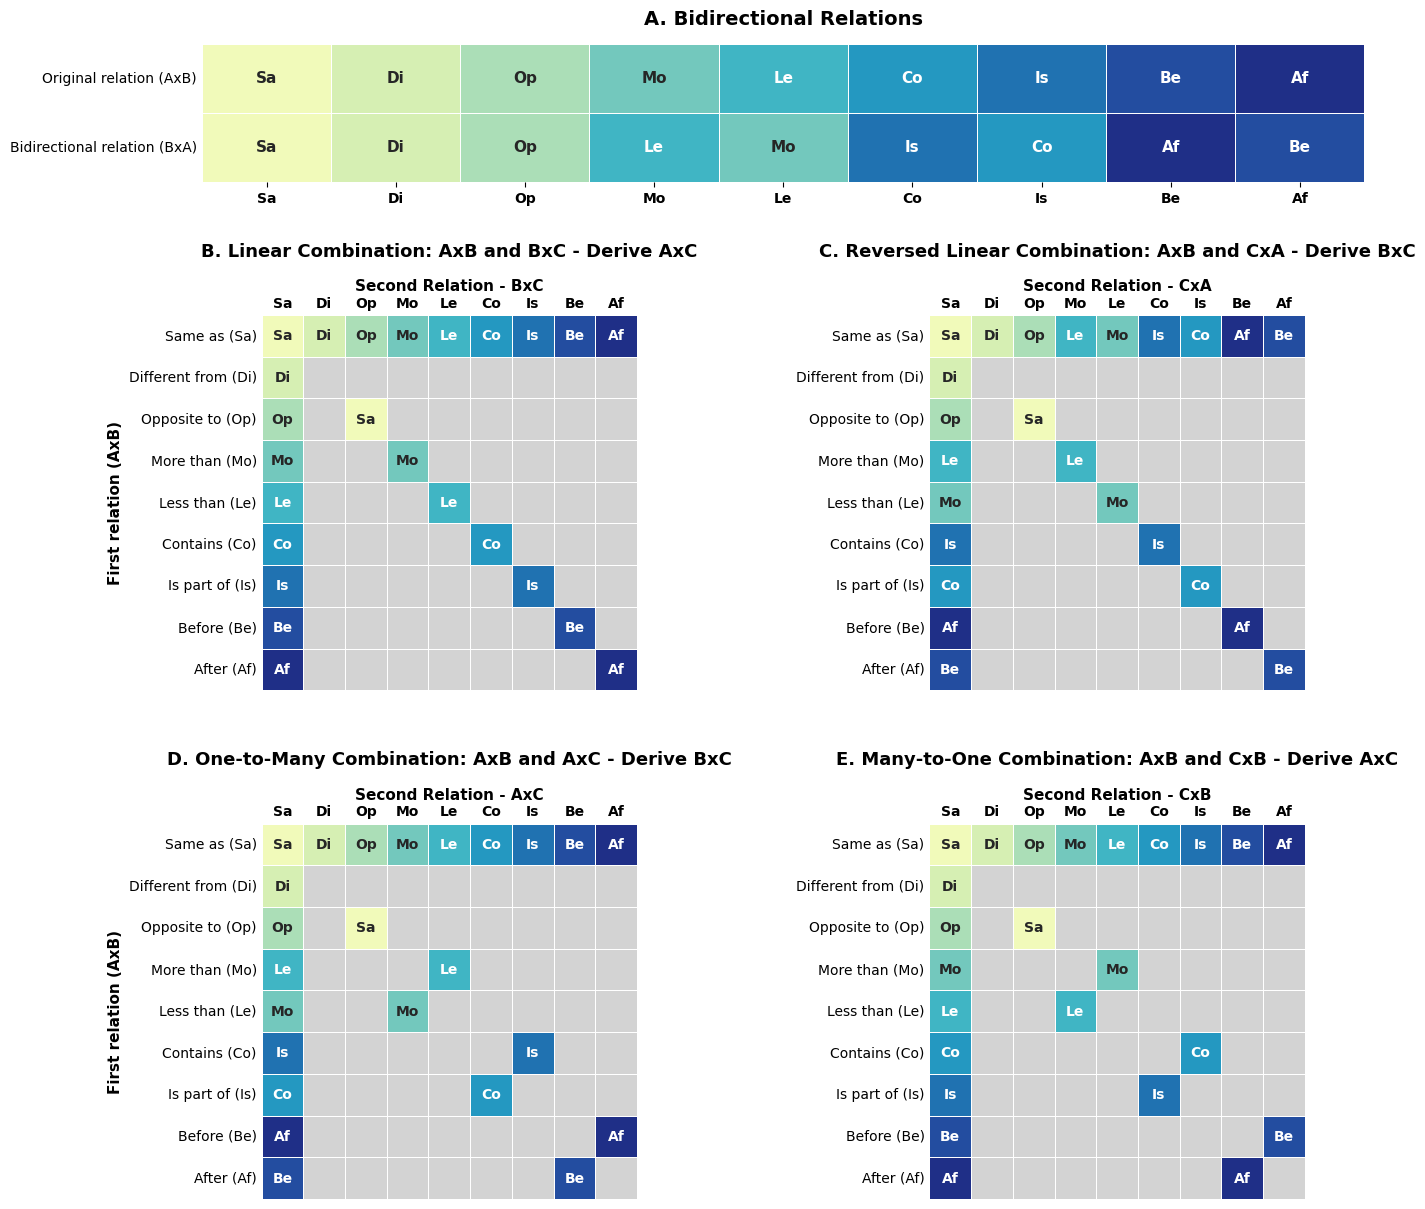

In [71]:
# If no relations are specified when function is called, tables are by default 
# created for all currently supported relations

plotTables = True
mutual, combi, relations = createDerivationTables(plotTables= True)



### 1.2 Small example: sameness, difference, and opposition

A smaller relation set often yields more interpretable figures. 

Setting  displays the generated mutual-entailment and combinatorial-entailment tables.

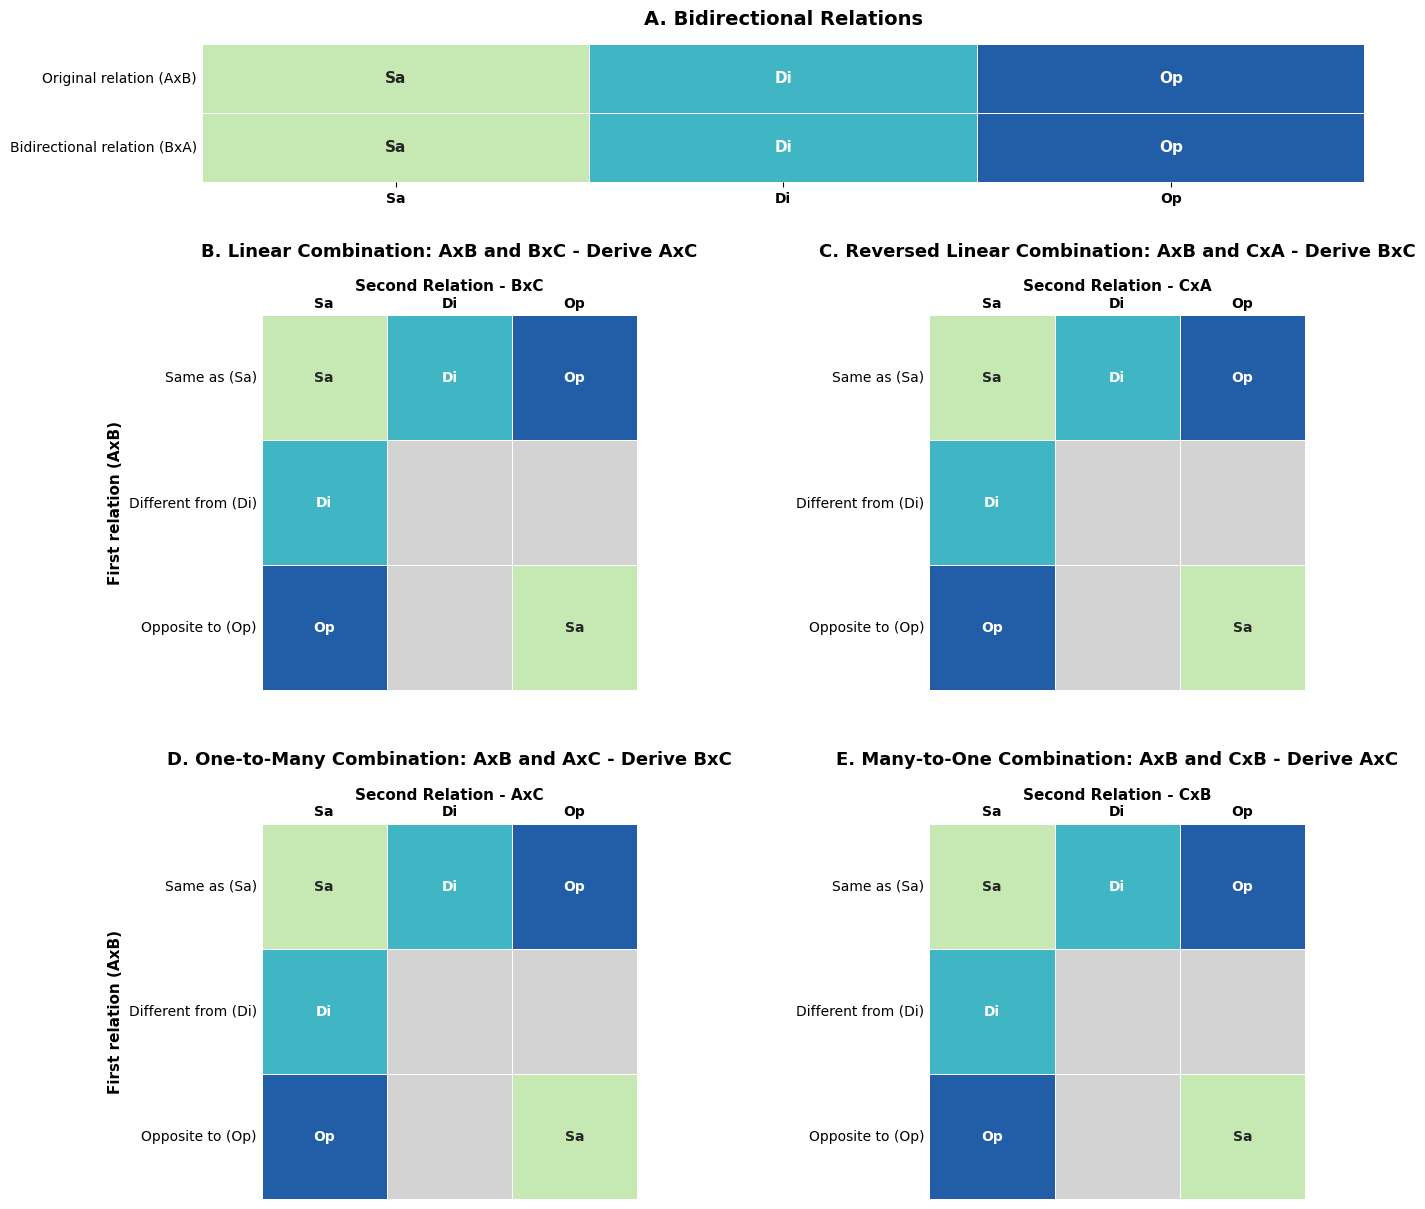

Completed relation vocabulary: ['Same as', 'Different from', 'Opposite to']


In [72]:
basic_relations = ['Same', 'Different', 'Opposite']
mutual_basic, combi_basic, relations_basic = createDerivationTables(
    basic_relations,
    plotTables=True
)
print('Completed relation vocabulary:', list(relations_basic))

### 1.3 Input completion: a directed comparative relation

Some relations require an inverse to express mutual entailment. For example, a requested *More* relation may trigger inclusion of its inverse (i.e., the inverse relation is added to the tables). The exact closure of the vocabulary is determined by the installed table-definition code.

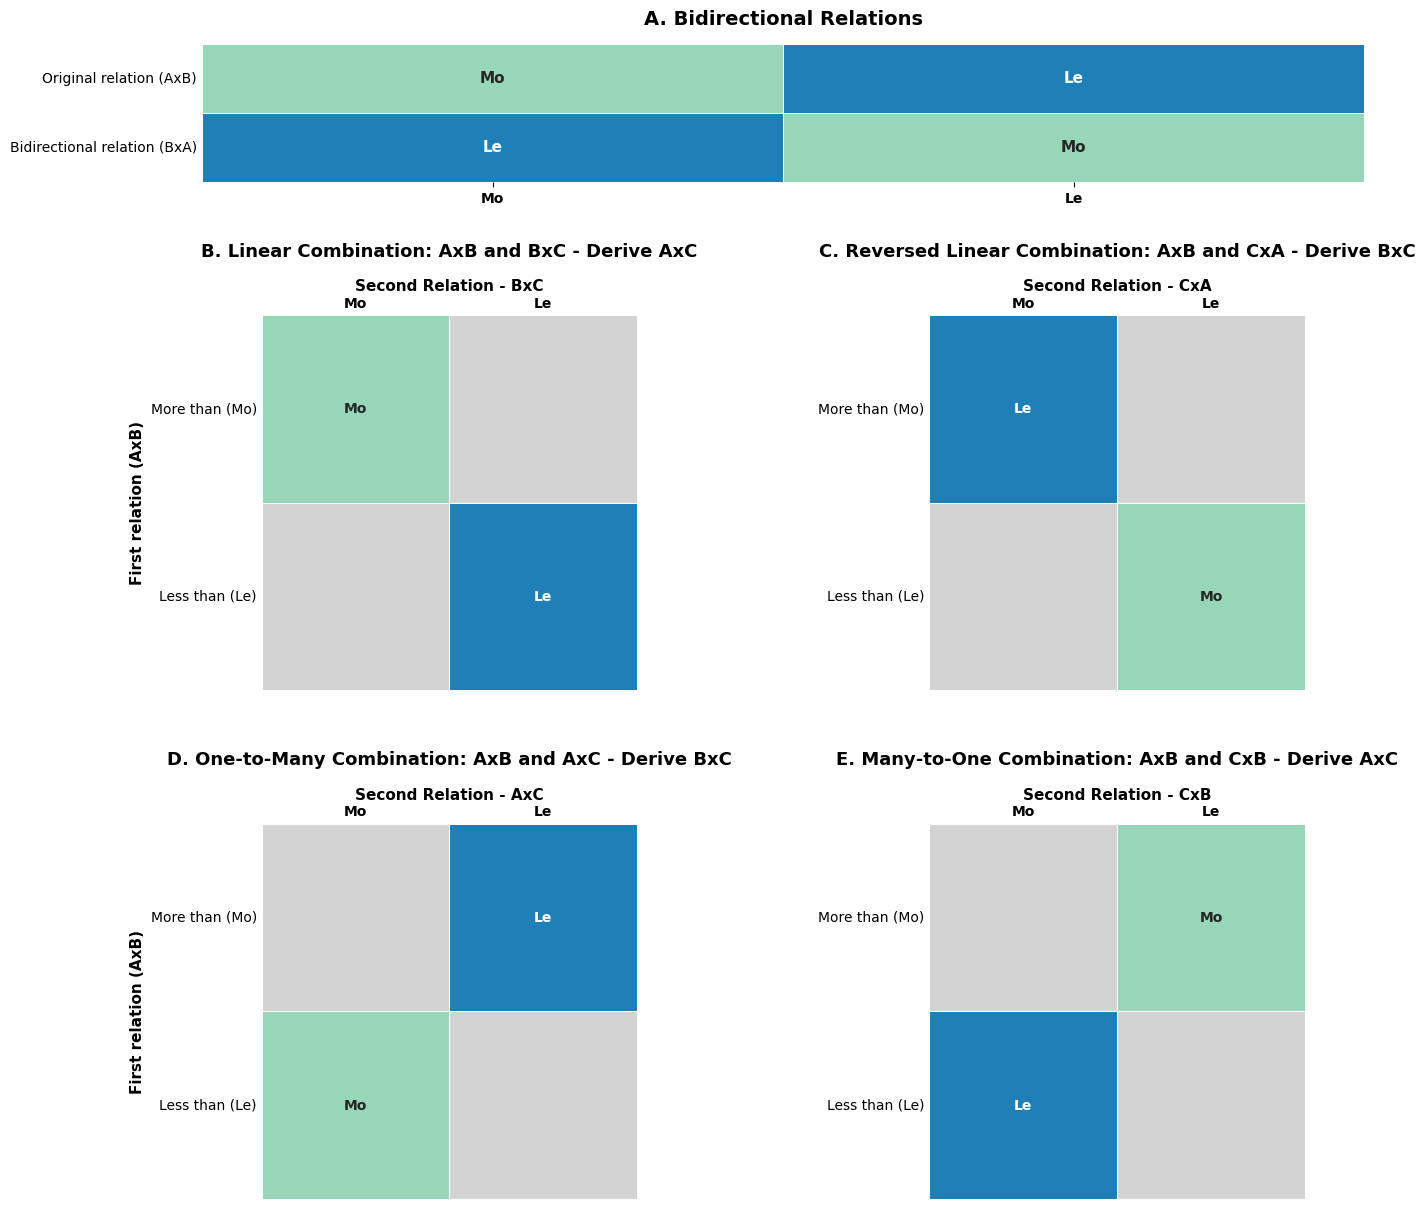

Requested: ['More']
Available after completion: ['More than', 'Less than']


In [73]:
mutual_more, combi_more, relations_more = createDerivationTables(
    ['More'], plotTables=True
)
print('Requested:', ['More'])
print('Available after completion:', list(relations_more))

Composing two opposition relations can yield sameness. This example highlights why the vocabulary used by a derivation table may be larger than the list entered by the user.

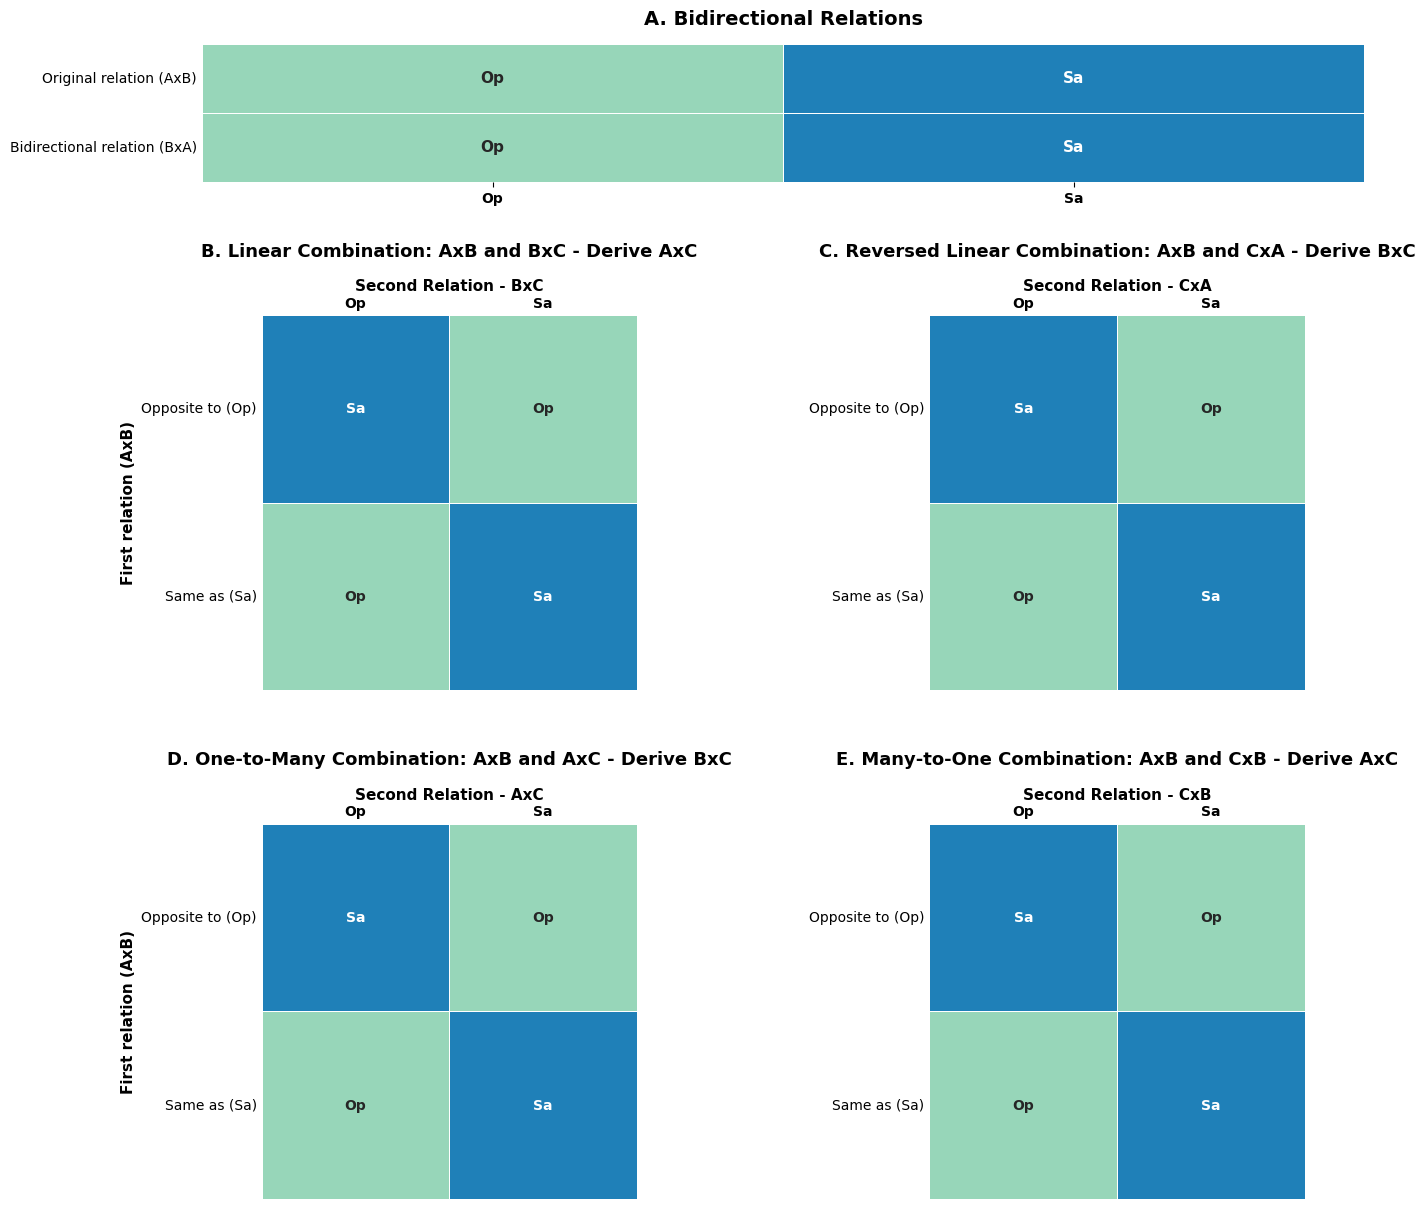

Requested: ['Opposite']
Available after completion: ['Opposite to', 'Same as']


In [74]:
mutual_opp, combi_opp, relations_opp = createDerivationTables(
    ['Opposite'], plotTables=True
)
print('Requested:', ['Opposite'])
print('Available after completion:', list(relations_opp))

### 1.4 Quick reference: table-generation parameters

| Parameter | Example | Purpose |
|---|---|---|
| First argument | `['Same', 'Different', 'Opposite']` | Select the initial relational vocabulary |
| First argument omitted | *(none)* | Use the library's default supported relations |
| `plotTables` | `False` | Inspect data without making figures |
| `plotTables` | `True` | Visualize mutual and four combinatorial tables |

**Interpretation:** A table entry licenses a possible symbolic derivation. It does not establish that a human participant would necessarily derive that relation in a behavioral experiment.

### 1.5 Create your own tables
Add any number of relations to the 'relations' list in the chunk below, then run the cell to generate the derivation tables for them. You can choose from the following relations:
'Same as',  'Different from', 'Opposite to', 'More than', 'Bigger than', 'Larger than', 'Faster than', 'Stronger than', 'Better than', 'Longer than',
 'Less than', 'Smaller than', 'Slower than', 'Weaker than', 'Worse than', 'Shorter than', 'Before', 'After', 'Contains', 'Is part of', 'Left of', 'Right of',  'In front', 'Behind', 'Heavier than', 'Lighter than', 'Older than', 'Younger than', 'Wider than', 'Narrower than', 'Louder than',
 'Quieter than', 'Farther than', 'Closer than', 'Higher than', 'Lower than', 'Earlier than', 'Later than', 'North of', 'South of', 'Taller than',
 'Not as tall as'

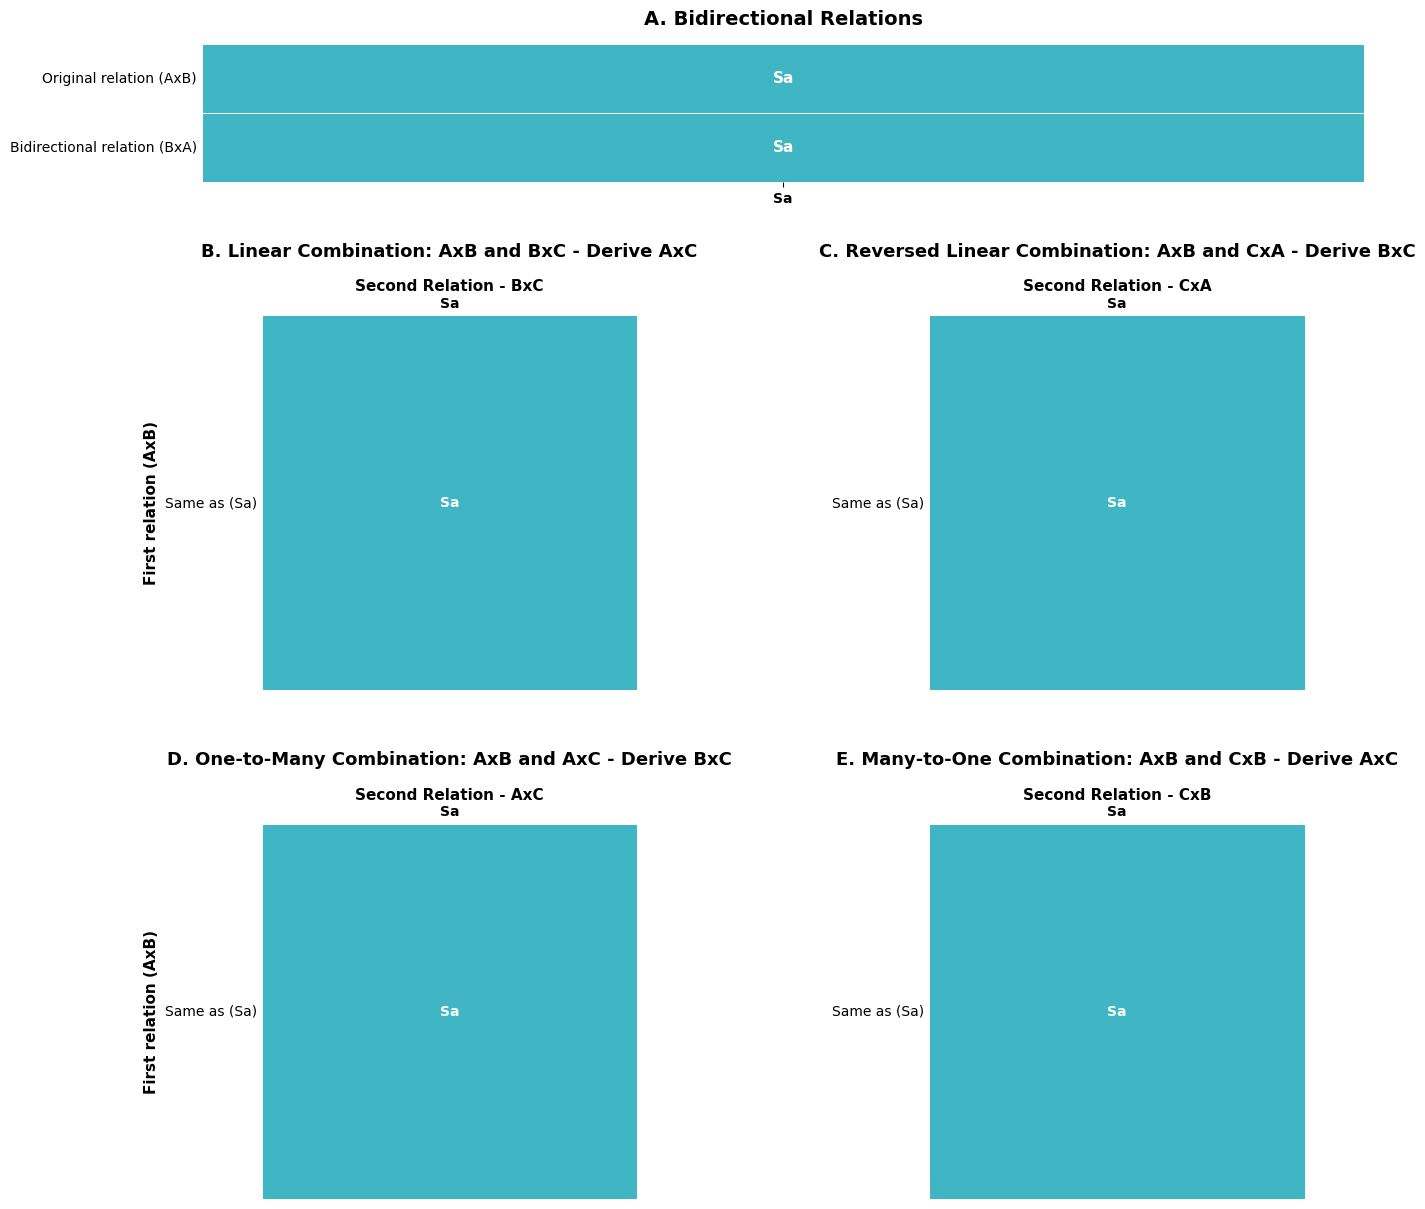

In [75]:
relations = ['same'] # <-- specify relations here in quotes, separated by commas

# Generate tables and plot
mutual, combi, relations = createDerivationTables(relations, plotTables = True)


## 2. Automated Relational Derivation

The derivation tables can be used to automate relational derivation, which can be used in various applications as will be illustrated below.

`deriveRelationsFromBaseline()` takes a dictionary of baseline relations and a stimulus-label list, then computes derived relations implied by the relation tables. The inputs use **integer indices into `sLabs`**, not the stimulus labels themselves. For example, `(0, 1)` refers to the first and second stimuli.

The returned objects are `relTab` (a relational table/representation) and `derived` (derived relations). The precise representation depends on the version of the installed project code.

### 2.1 A mixed relational network (Steele & Hayes, 1991)
For instance, if we provide some stimulus labels, we can recreate the network
trained by Steele and Hayes (1991), with six baseline relations:
<ul>
    <li> A same as B1 </li>
    <li> A same as C1 </li>
    <li> A different from B3 </li>
    <li> A different from C3 </li>
    <li> A opposite to B2, A opposite to C2 </li>
</ul>

Note that `N1` and `N2` are included in the label list but not connected by these baseline training relations.

The `illustrate='print'` prints out the derived relations step-by-step.

In [76]:
stimuli_mixed = ['A', 'B1', 'B2', 'B3', 'C1', 'C2', 'C3', 'N1', 'N2']
baseline_mixed = {
    'Same as': [(0, 1), (0, 4)],
    'Different from': [(0, 3), (0, 6)],
    'Opposite to': [(0, 2), (0, 5)],
}

for relation, pairs in baseline_mixed.items():
    for left, right in pairs:
        print(f'{stimuli_mixed[left]} — {relation} — {stimuli_mixed[right]}')

relTab_mixed, derived_mixed = deriveRelationsFromBaseline(
    baseline_mixed,
    stimuli_mixed,
    illustrate='print'
)

A — Same as — B1
A — Same as — C1
A — Different from — B3
A — Different from — C3
A — Opposite to — B2
A — Opposite to — C2


### 2.2 Visualize the **same** network in three ways

The `illustrate` option changes *how* the results are displayed, not the baseline network being derived. Use `print` when auditing individual consequences, `heatmap` for dense relational patterns, and `graph` to communicate network structure.

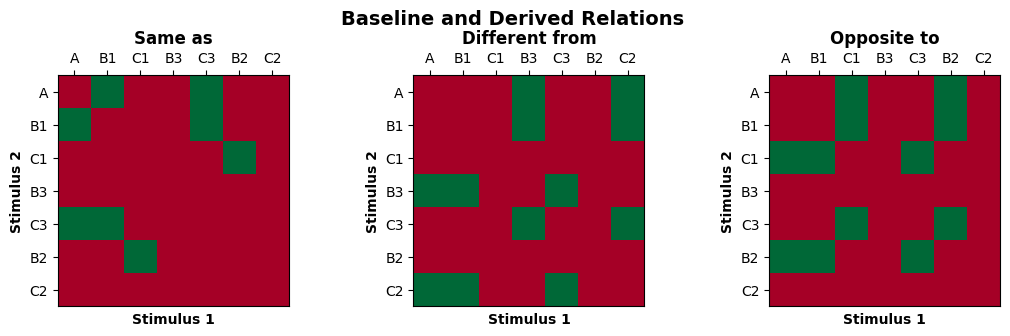

In [77]:
relTab_mixed_heat, derived_mixed_heat = deriveRelationsFromBaseline(
    baseline_mixed, stimuli_mixed, illustrate='heatmap'
)

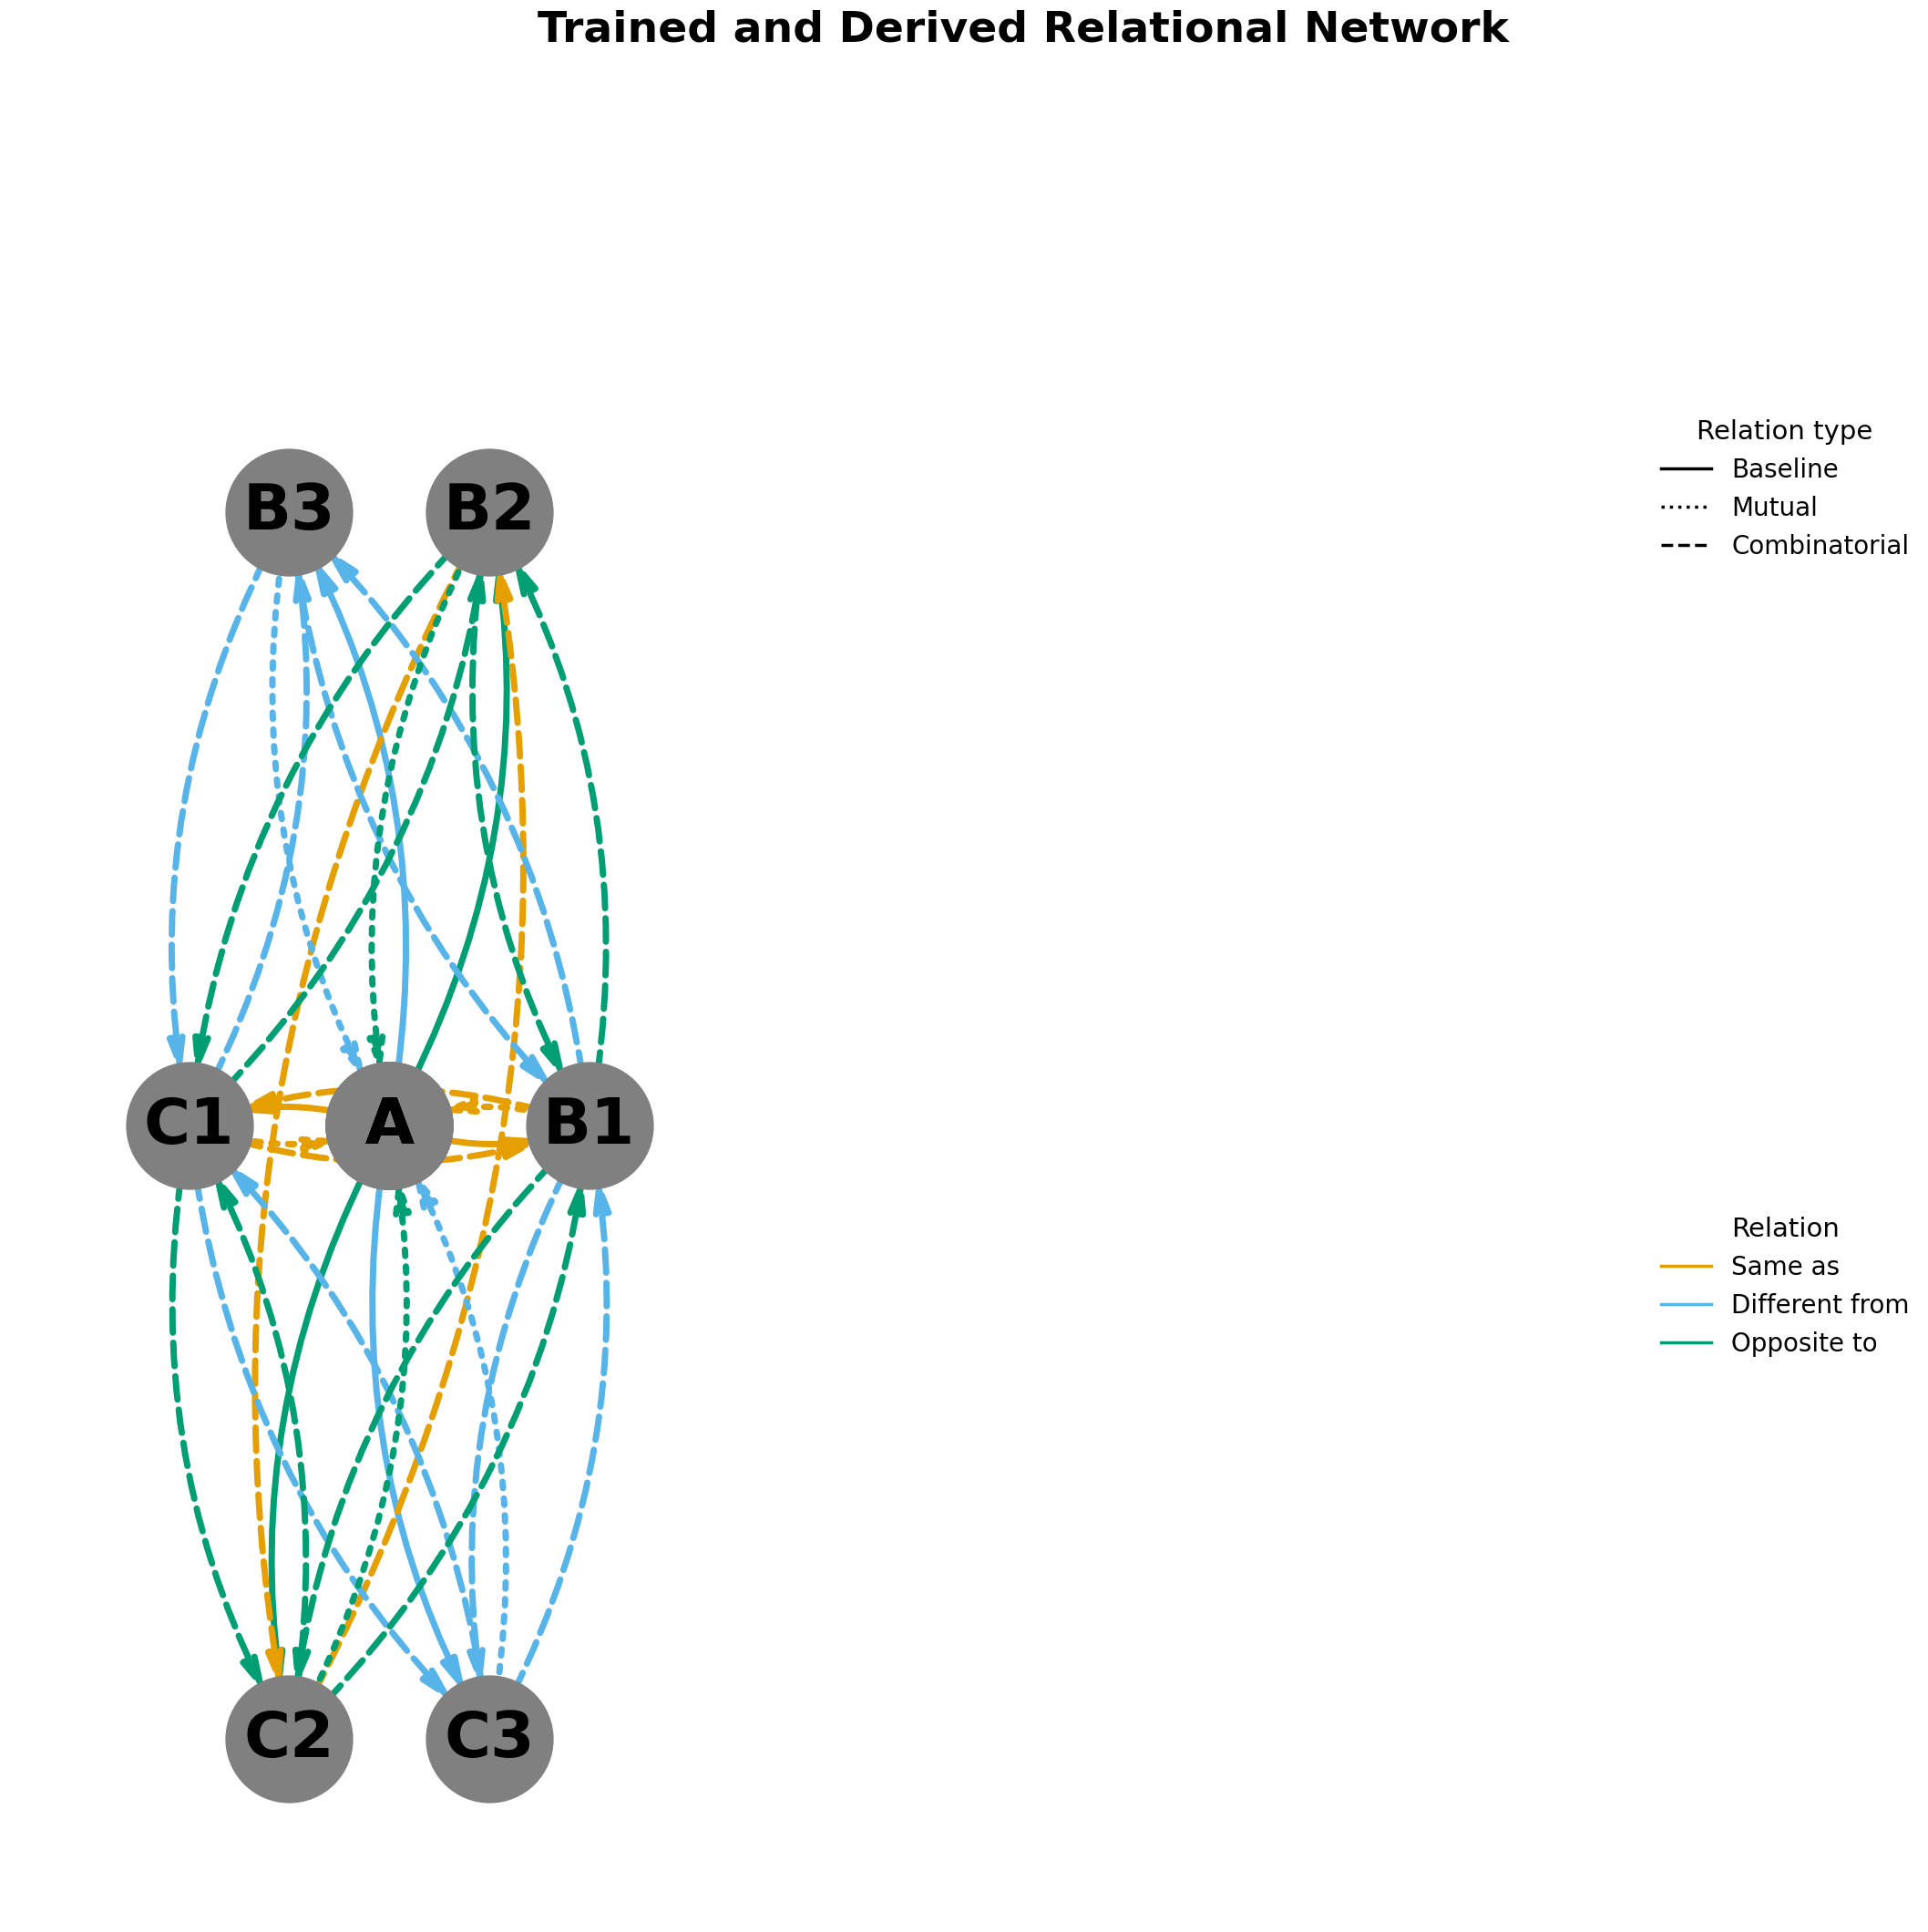

In [78]:
relTab_mixed_graph, derived_mixed_graph = deriveRelationsFromBaseline(
    baseline_mixed, stimuli_mixed, illustrate='graph'
)

### 2.3 A seven-item transitive-inference chain

This example trains only adjacent *More than* relations: A > B > C > D > E > F > G. Nonadjacent consequences such as A > G require composition across multiple baseline links. `max_depth=None` requests unrestricted depth where supported by the function; the number of distinct stimuli still bounds simple paths in a finite network.

This use case is well suited to studying **symbolic/nodal distance** and to inspecting whether an algorithm derives long-range relations.

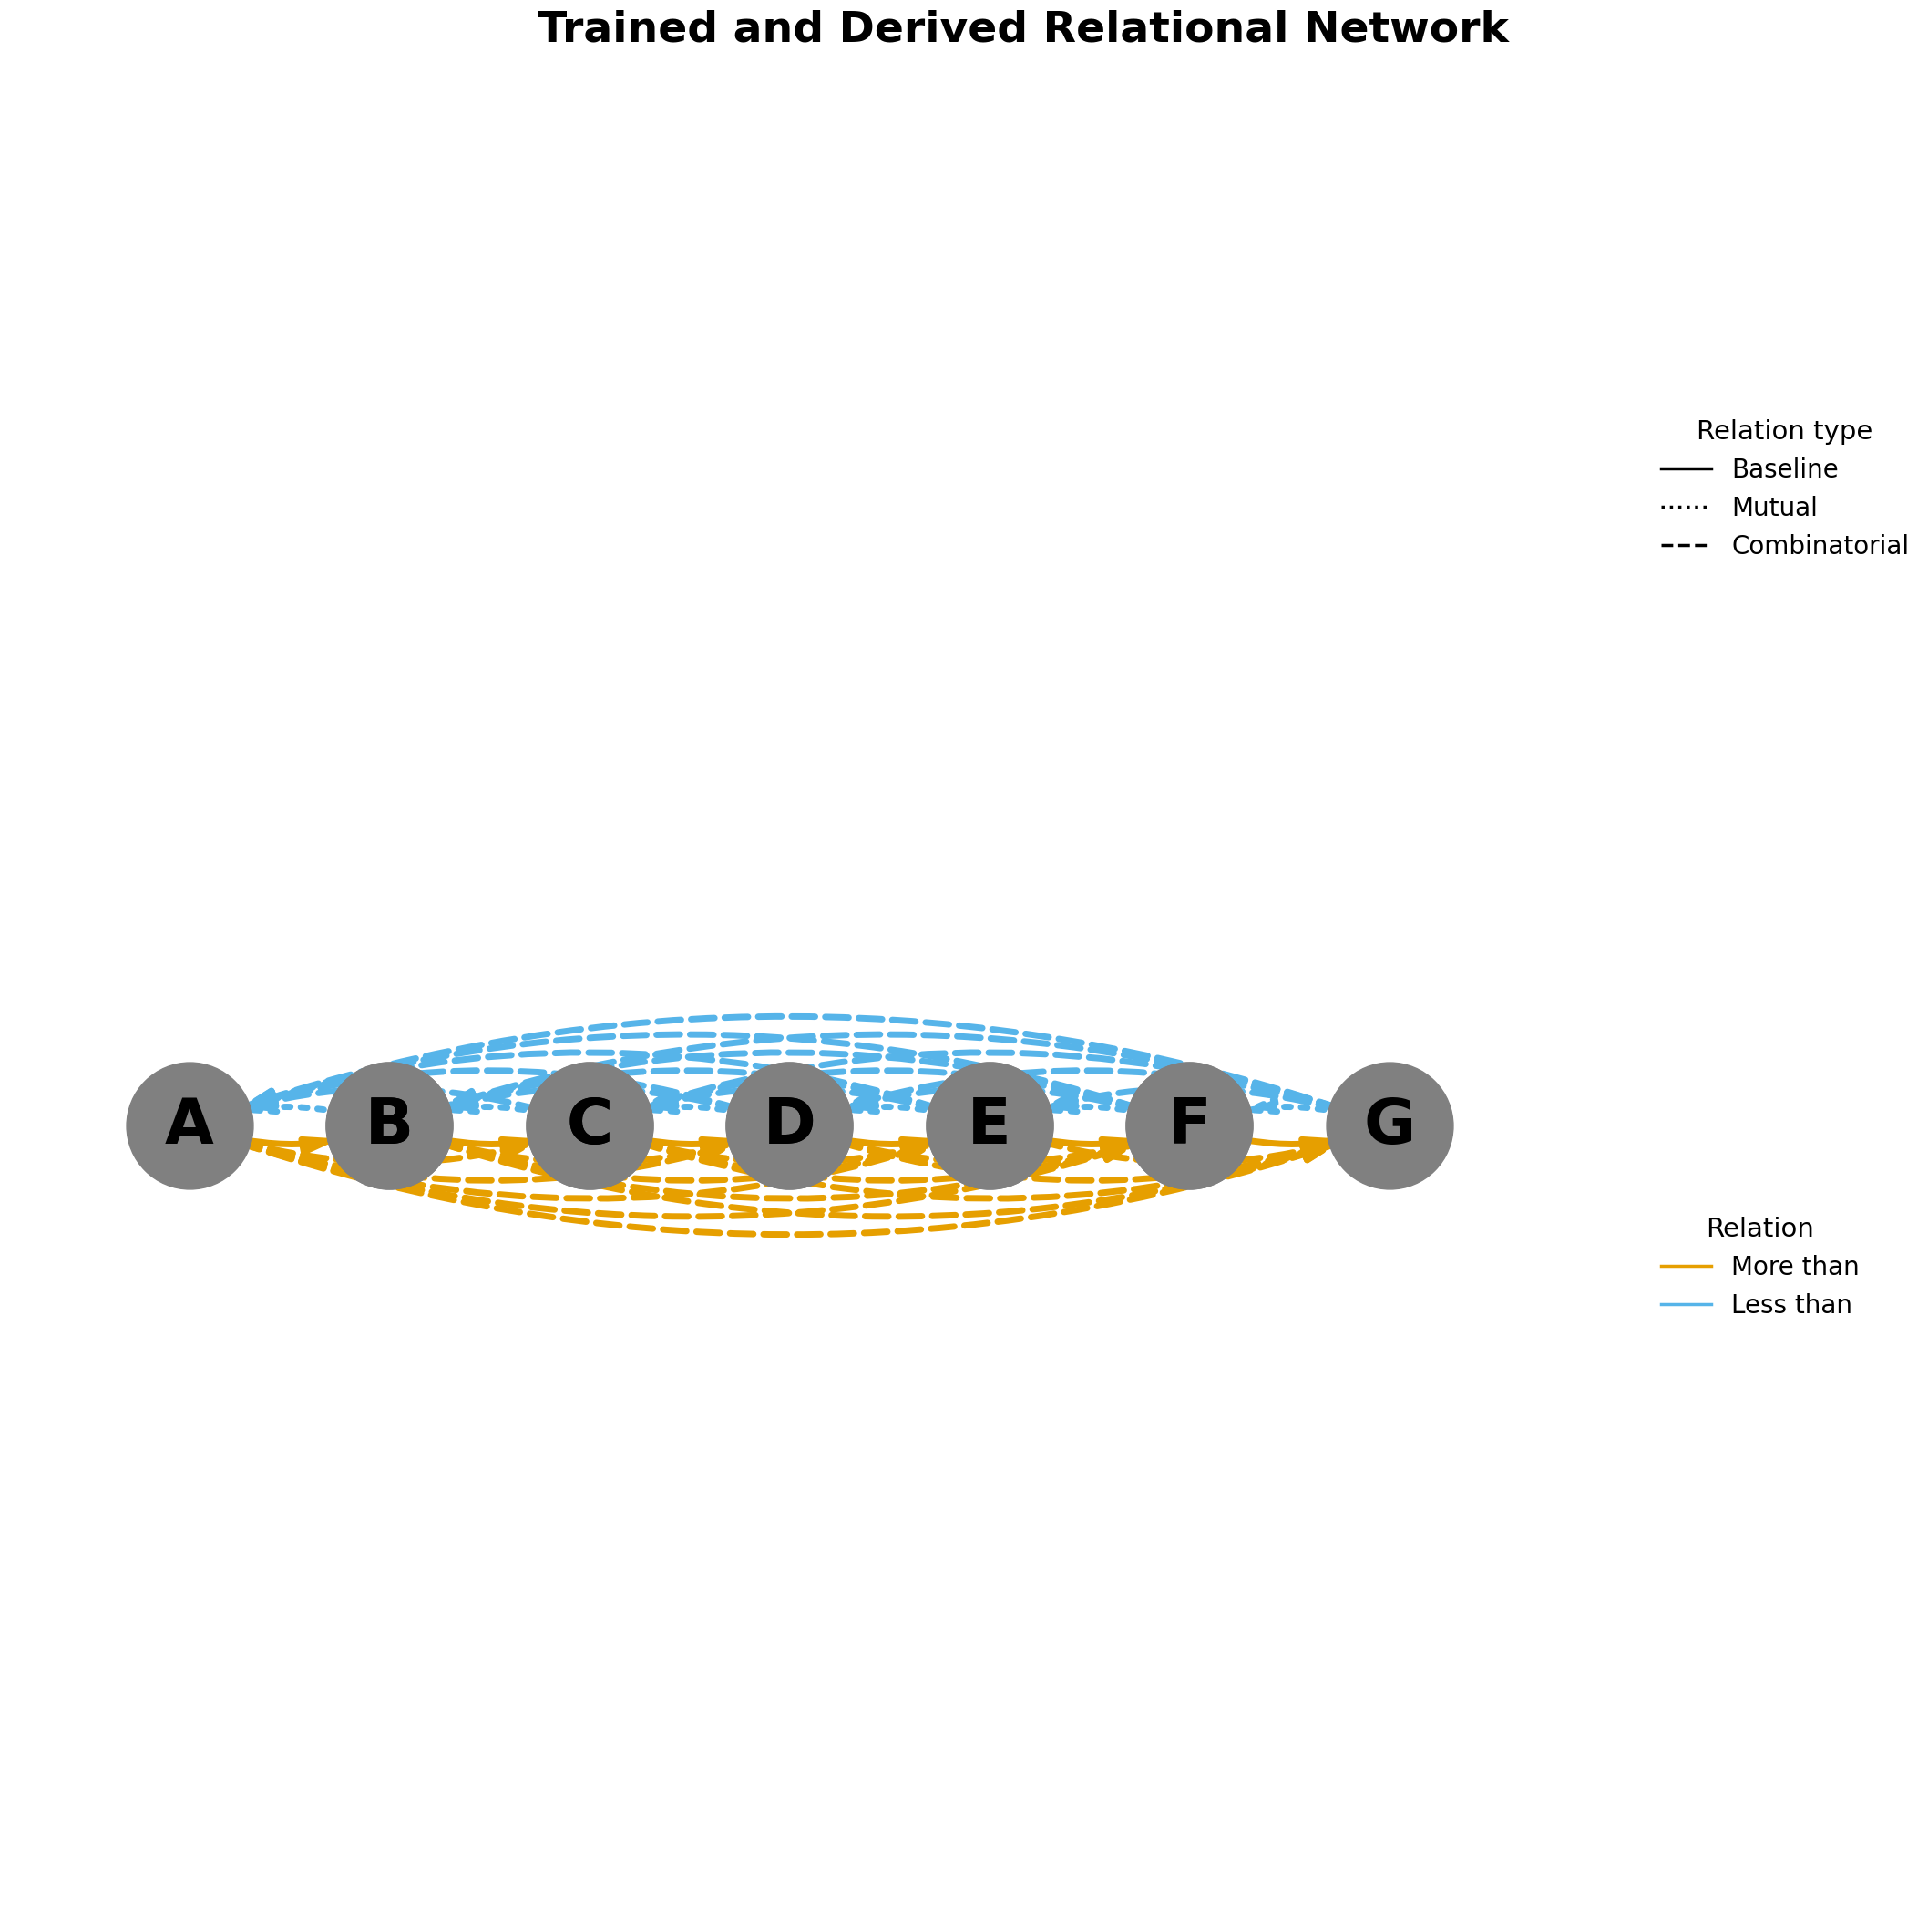

In [79]:
stimuli_chain = list('ABCDEFG')
baseline_chain = {
    'More than': [(i, i + 1) for i in range(len(stimuli_chain) - 1)]
}

relTab_chain, derived_chain = deriveRelationsFromBaseline(
    baseline_chain,
    stimuli_chain,
    illustrate='graph',
    max_depth=None
)

### 2.4 Compare shorter versus longer derivation depth

`max_depth` limits how far the algorithm can compose relations. It is particularly useful for demonstrations of limited derivation or for controlling computation. We rerun the same chain with a smaller depth limit and **inspect the returned outputs**, because the exact meaning and treatment of depth depend on the installed function version.

With a maximum derivation depth of 2, the derivation tables will show no derived relations of nodal distance 4 or more (e.g., A-F)

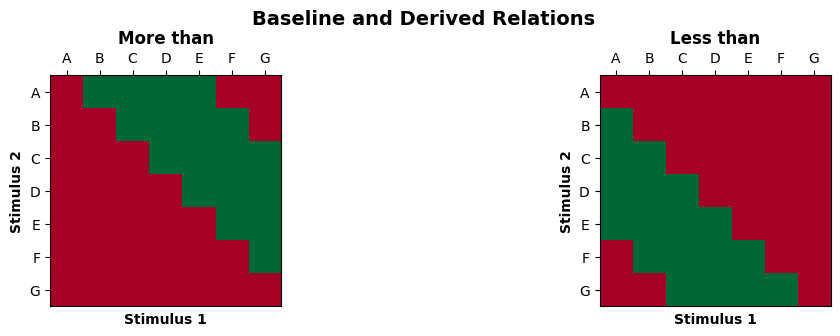

Return type (shallow): dict
Return type (unrestricted): dict
Top-level keys (shallow): ['More than', 'Less than']
Top-level keys (unrestricted): ['More than', 'Less than']


In [80]:
relTab_chain_shallow, derived_chain_shallow = deriveRelationsFromBaseline(
    baseline_chain,
    stimuli_chain,
    illustrate='heatmap',
    max_depth=2
)

print('Return type (shallow):', type(derived_chain_shallow).__name__)
print('Return type (unrestricted):', type(derived_chain).__name__)
if isinstance(derived_chain_shallow, dict) and isinstance(derived_chain, dict):
    print('Top-level keys (shallow):', list(derived_chain_shallow))
    print('Top-level keys (unrestricted):', list(derived_chain))

### 2.5 Training structure: Linear, one-to-many, and many-to-one

Another example is from stimulus equivalence research.
The same equivalence-class membership can be trained with different arrangements of baseline relations. The following networks all involve two three-member classes, but differ in which stimulus serves as sample or common node.

- **Linear:** A→B→C within each class.
- **One-to-many (OTM):** A→B and A→C.
- **Many-to-one (MTO):** A→C and B→C.



=== Linear ===


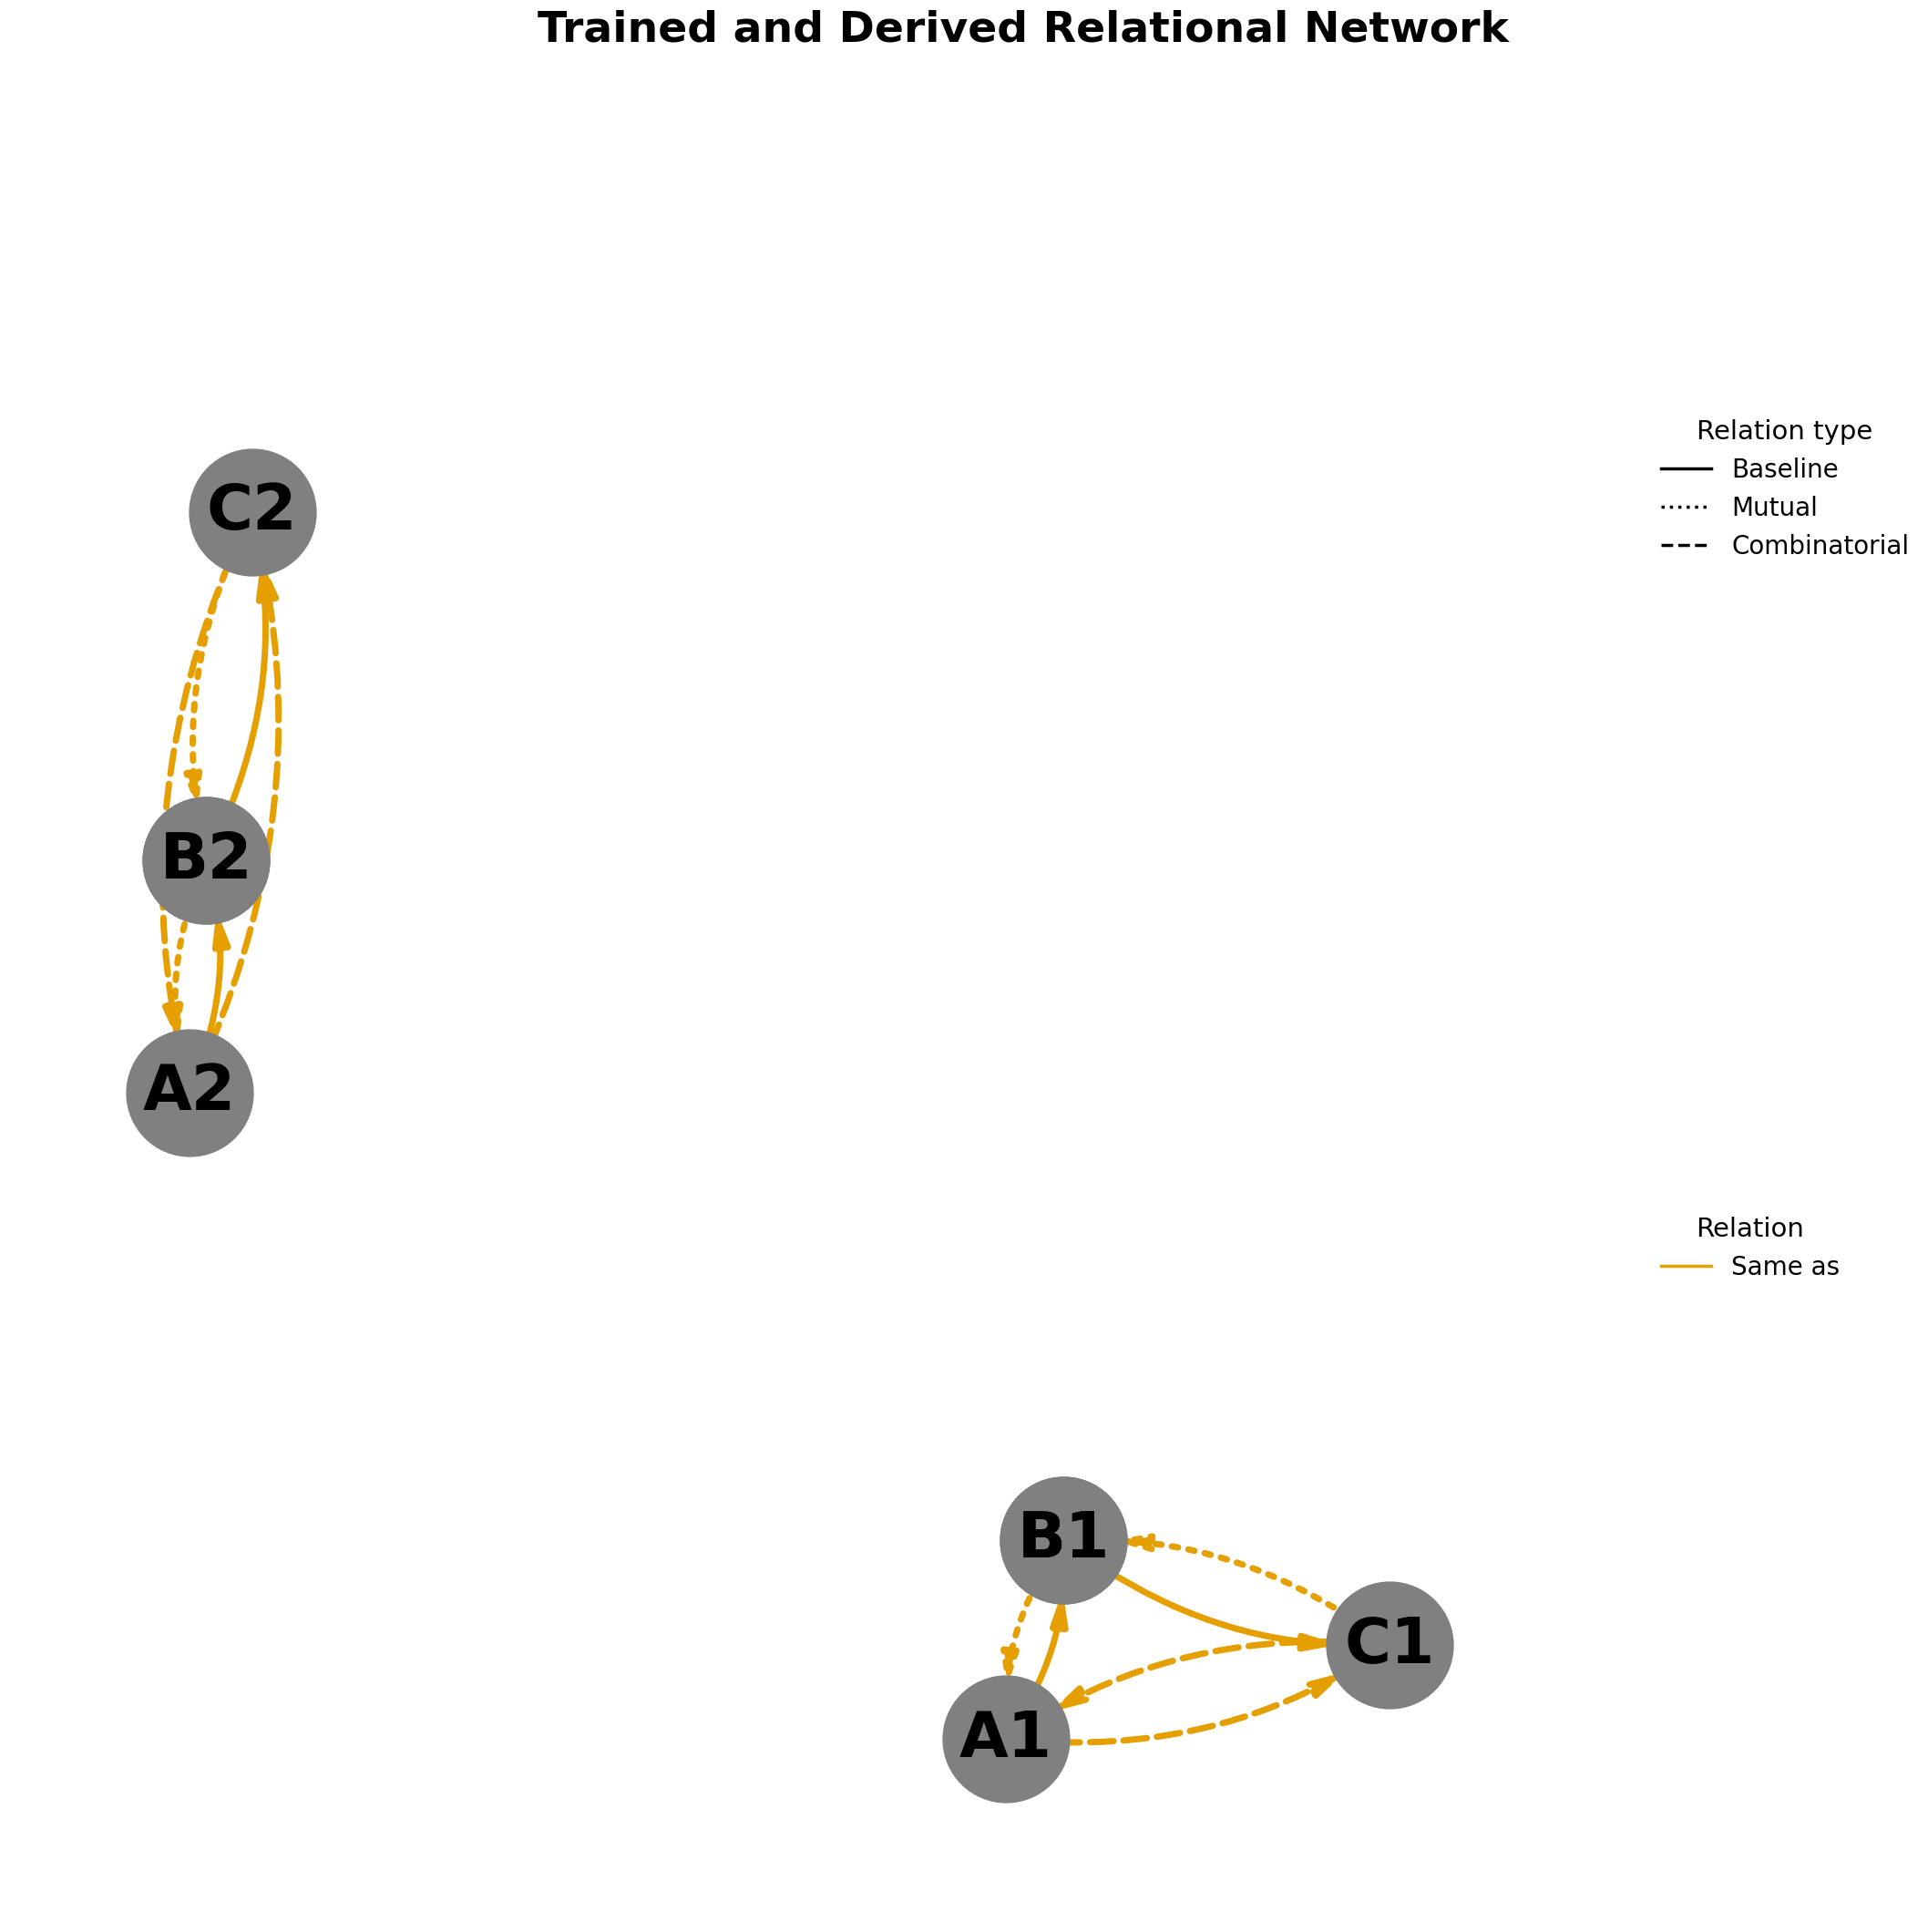


=== OTM ===


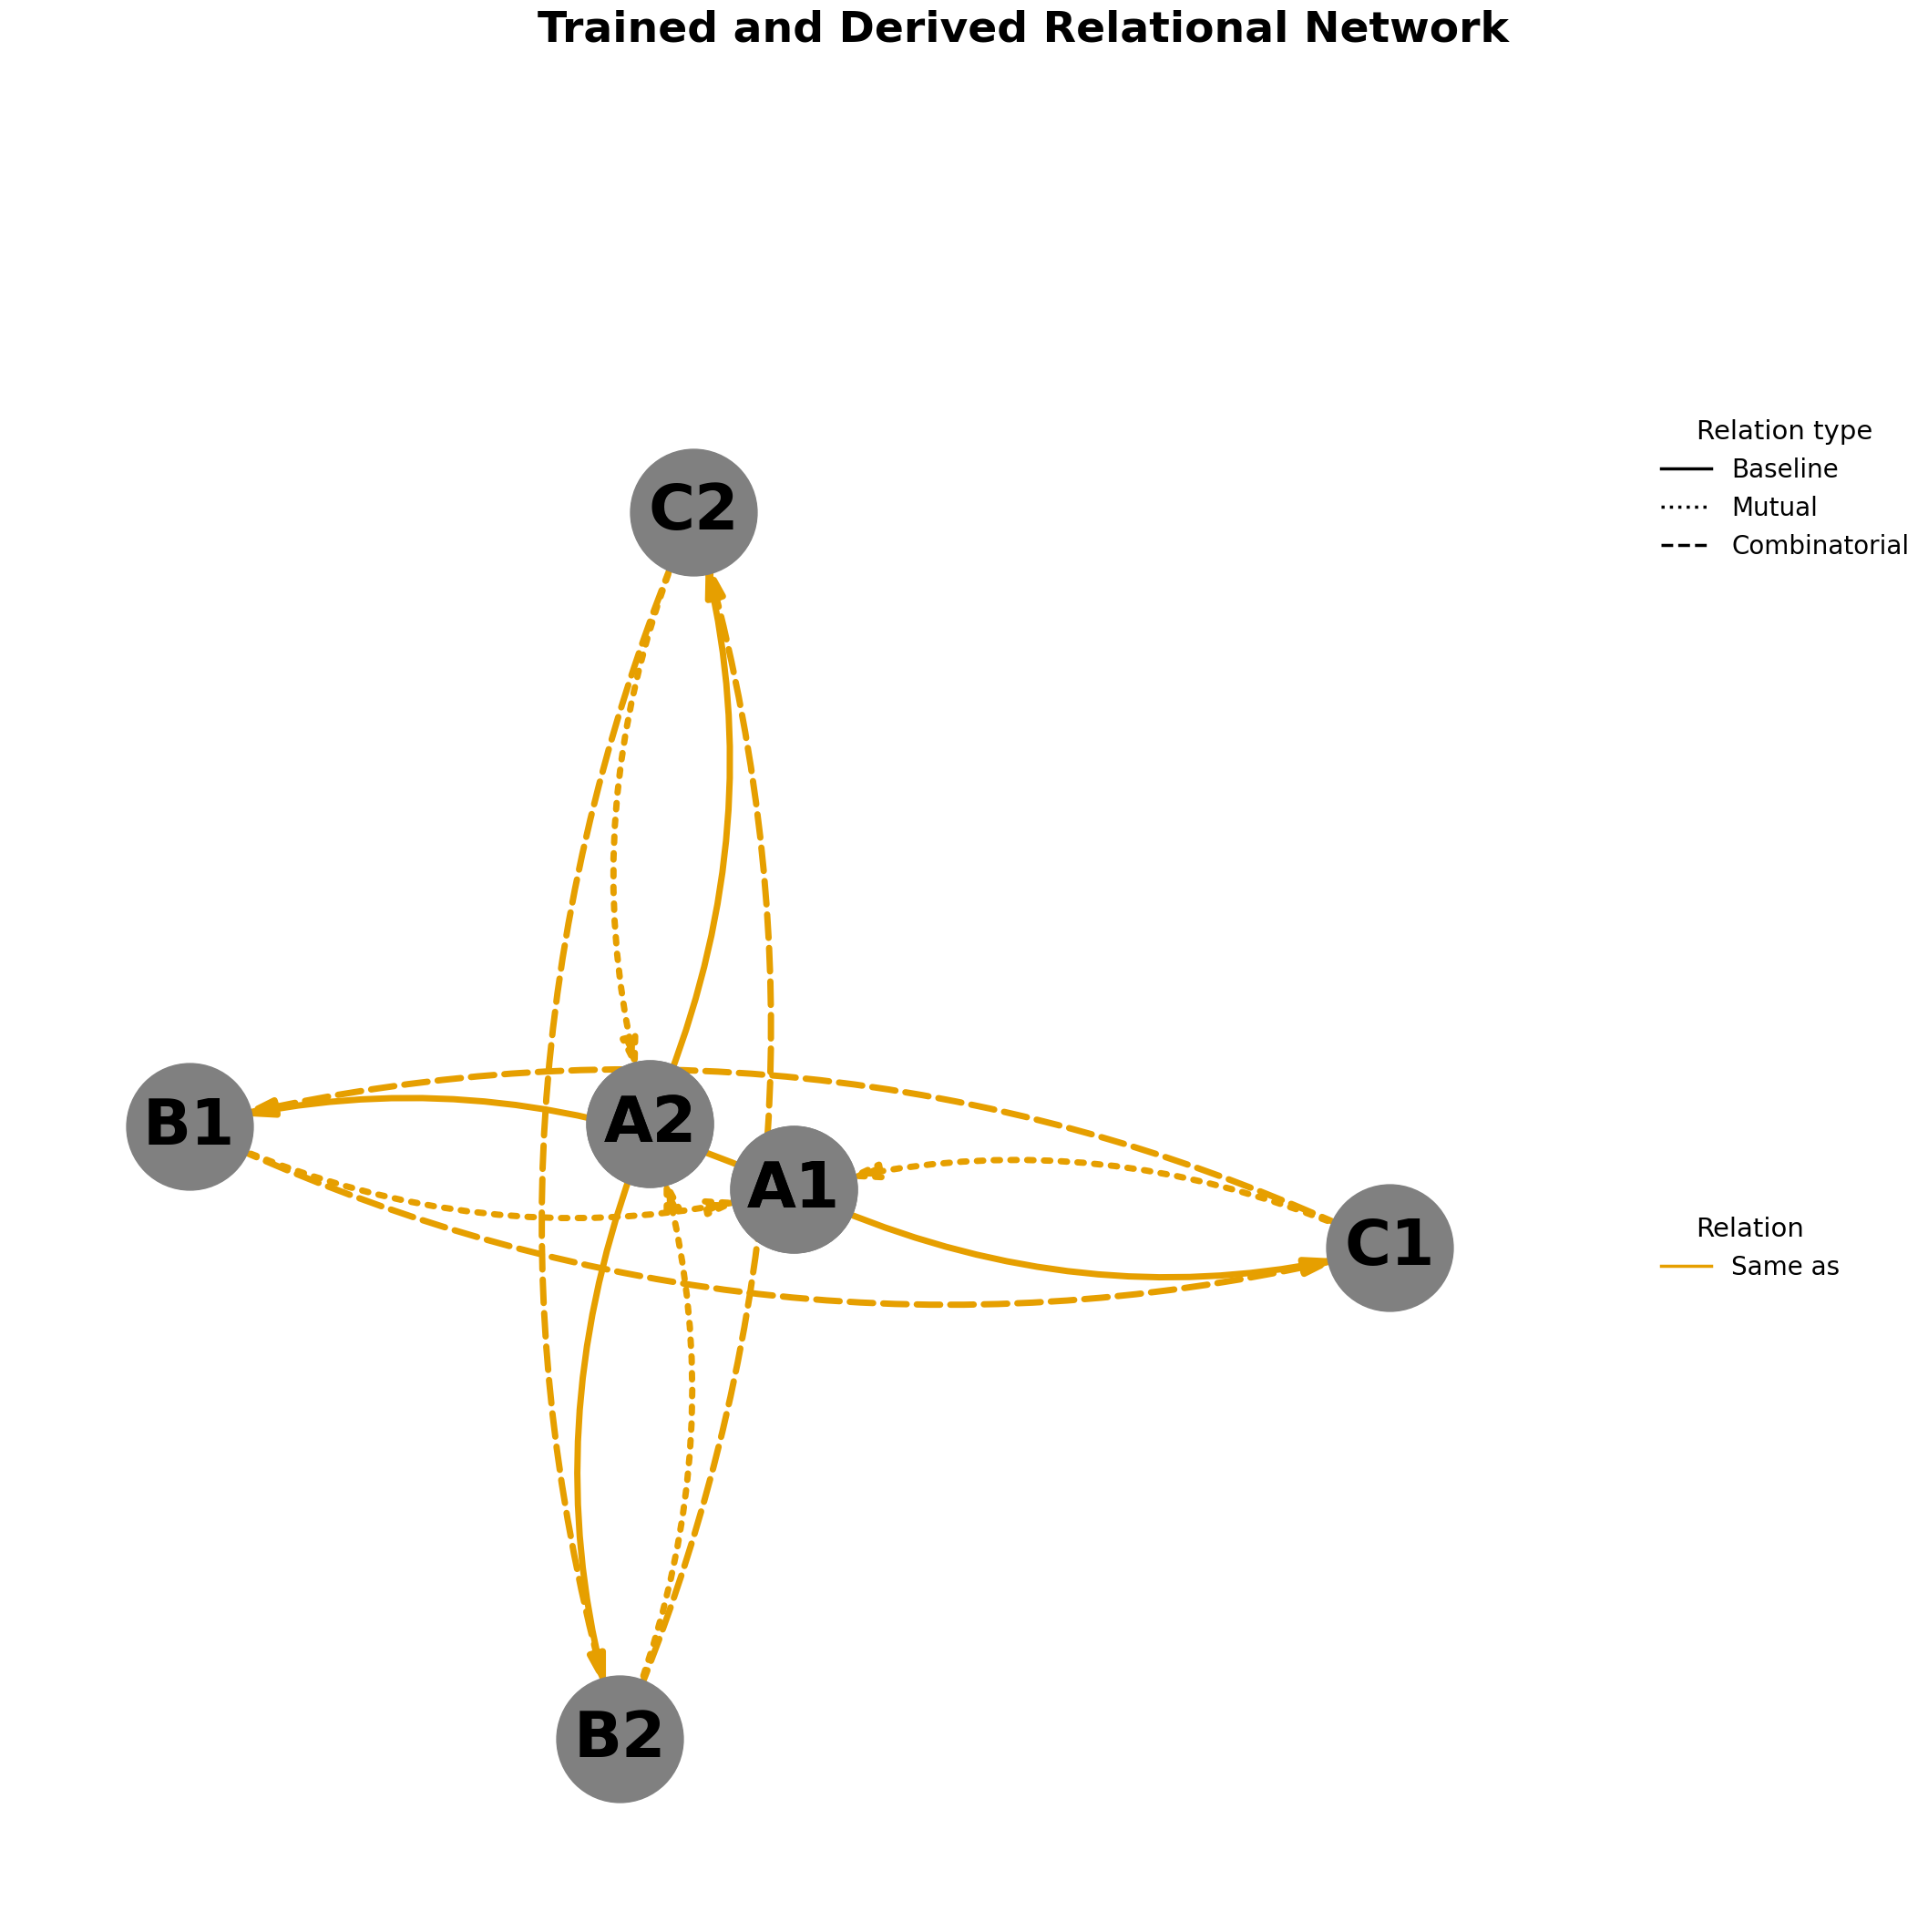


=== MTO ===


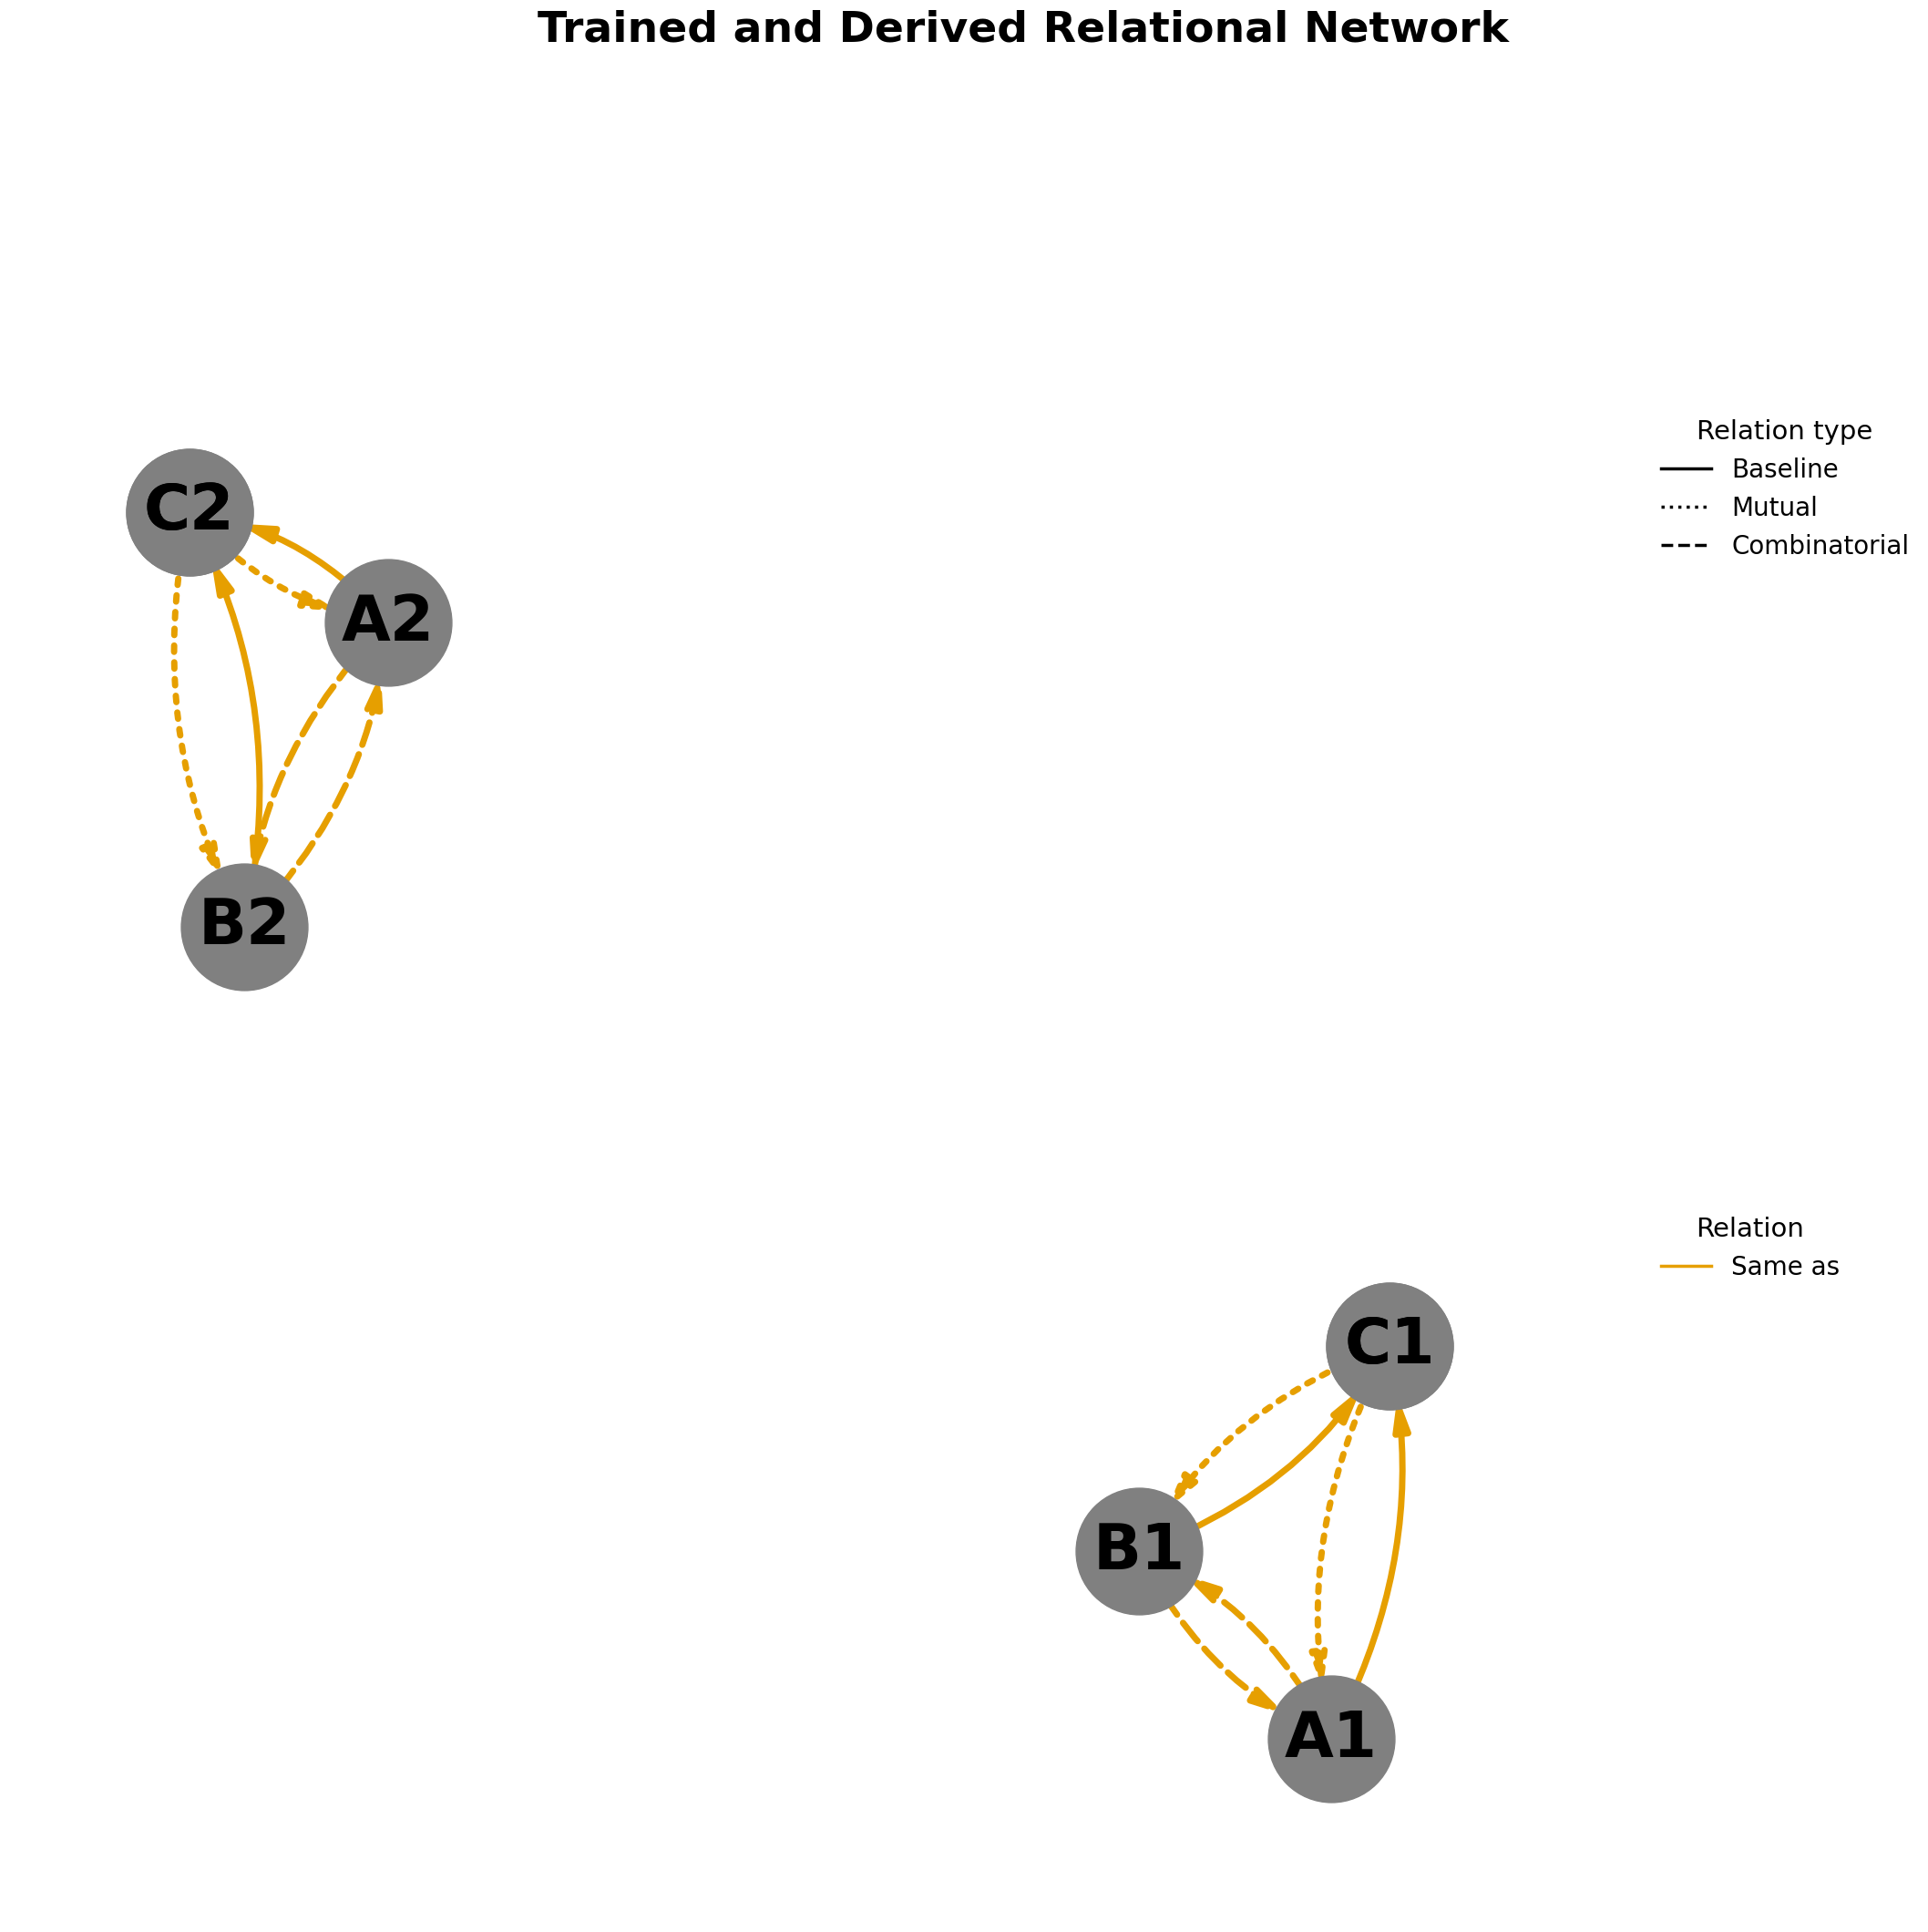

In [81]:
stimuli_classes = ['A1', 'B1', 'C1', 'A2', 'B2', 'C2']
structure_baselines = {
    'Linear': {'Same as': [(0, 1), (1, 2), (3, 4), (4, 5)]},
    'OTM':    {'Same as': [(0, 1), (0, 2), (3, 4), (3, 5)]},
    'MTO':    {'Same as': [(0, 2), (1, 2), (3, 5), (4, 5)]},
}

structure_derivations = {}
for structure, baseline in structure_baselines.items():
    print(f'\n=== {structure} ===')
    rel_tab, derived = deriveRelationsFromBaseline(
        baseline, stimuli_classes, illustrate='graph'
    )
    structure_derivations[structure] = {'relTab': rel_tab, 'derived': derived}

### 2.6 Visualize a selected network with the dedicated graph utility

The existing project also provides `plotRelNetworkGraph`, which gives you direct control over displayed relation types and layout. This cell uses the arguments from the project's graph-plotting API.

Common settings include `layout='spring'`, `'circle'`, `'kamada_kawai'`, or `'grid'`; `plotRels` can be restricted to trained (`baseline`), mutual, or combinatorial relations. This is helpful when a fully annotated graph becomes crowded.

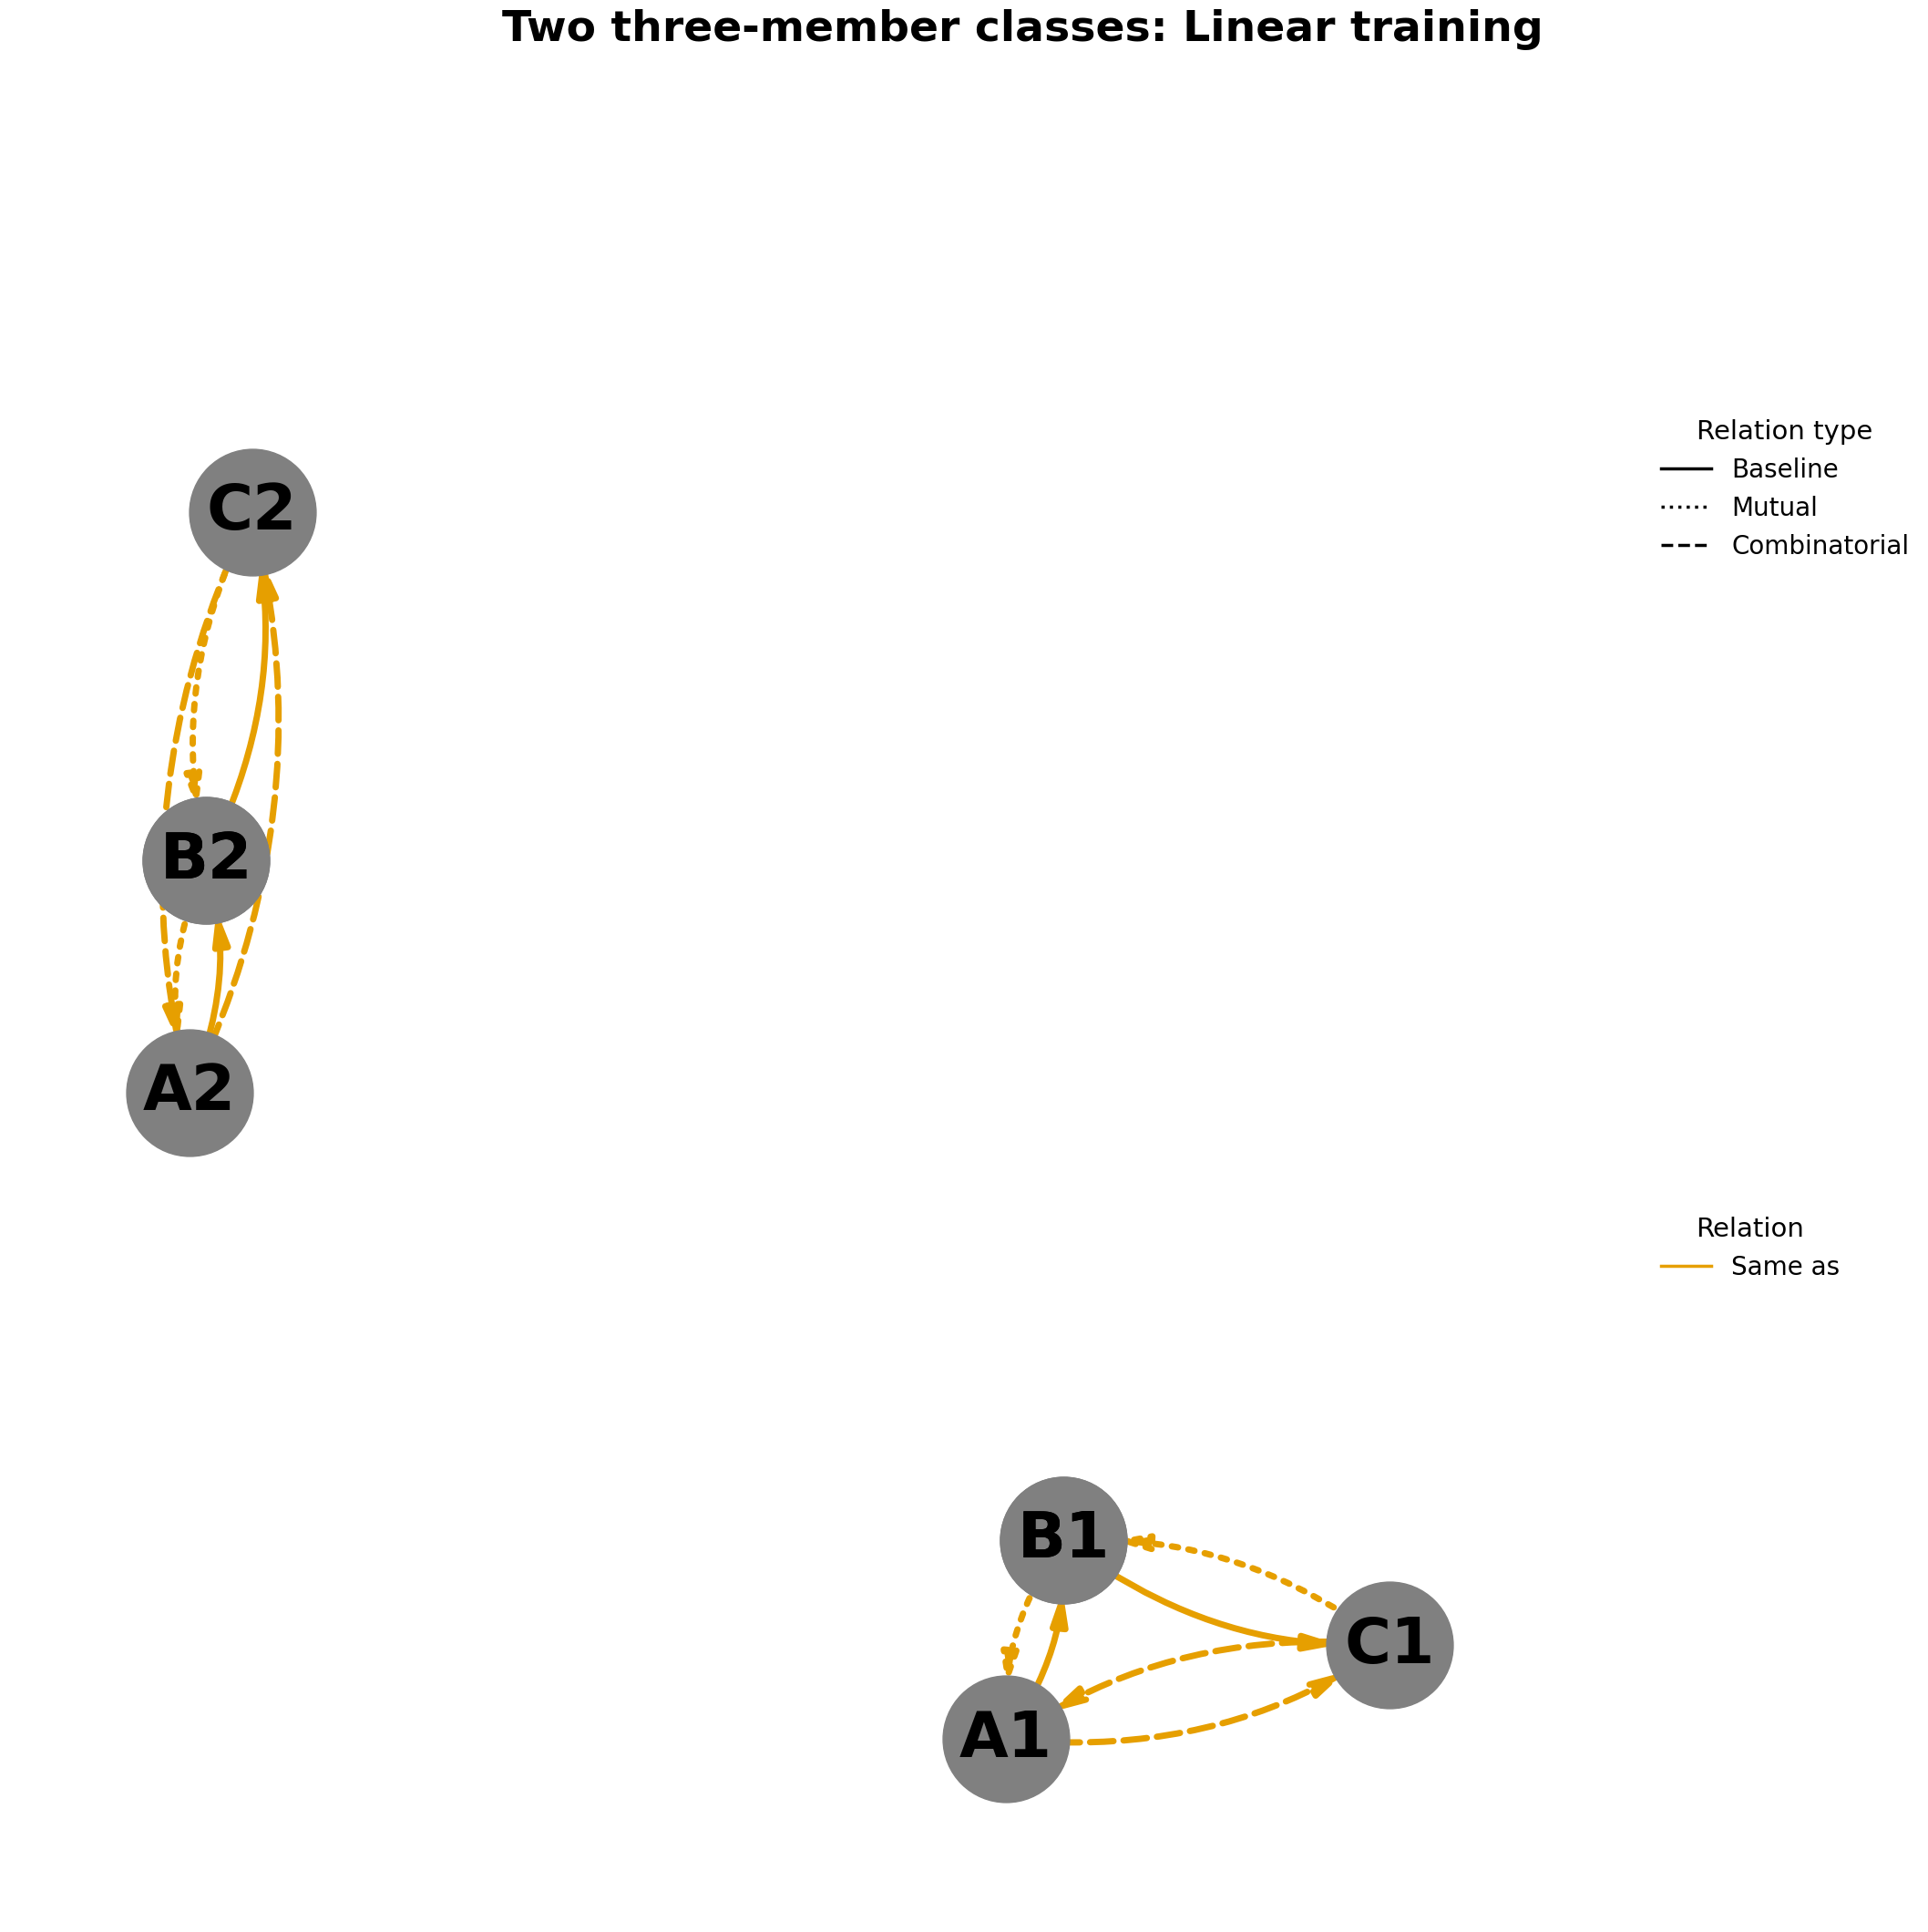

In [82]:
if 'plotRelNetworkGraph' not in globals():
    print('plotRelNetworkGraph is not exported by this version of derTables.plot_utils.')
else:
    plotRelNetworkGraph(
        structure_baselines['Linear'],
        derived=structure_derivations['Linear']['derived'],
        sLabs=stimuli_classes,
        plotRels=['baseline', 'mutual', 'combi'],
        plotTitle='Two three-member classes: Linear training',
        layout='spring'
    )

### 2.7 Alternative graph layout and only baseline relations

Use a circle arrangement and turn off derived relations to display the training contingencies by themselves. Exact accepted `plotRels` values and layouts can be checked against `inspect.signature(plotRelNetworkGraph)` and the project's visualizer documentation.

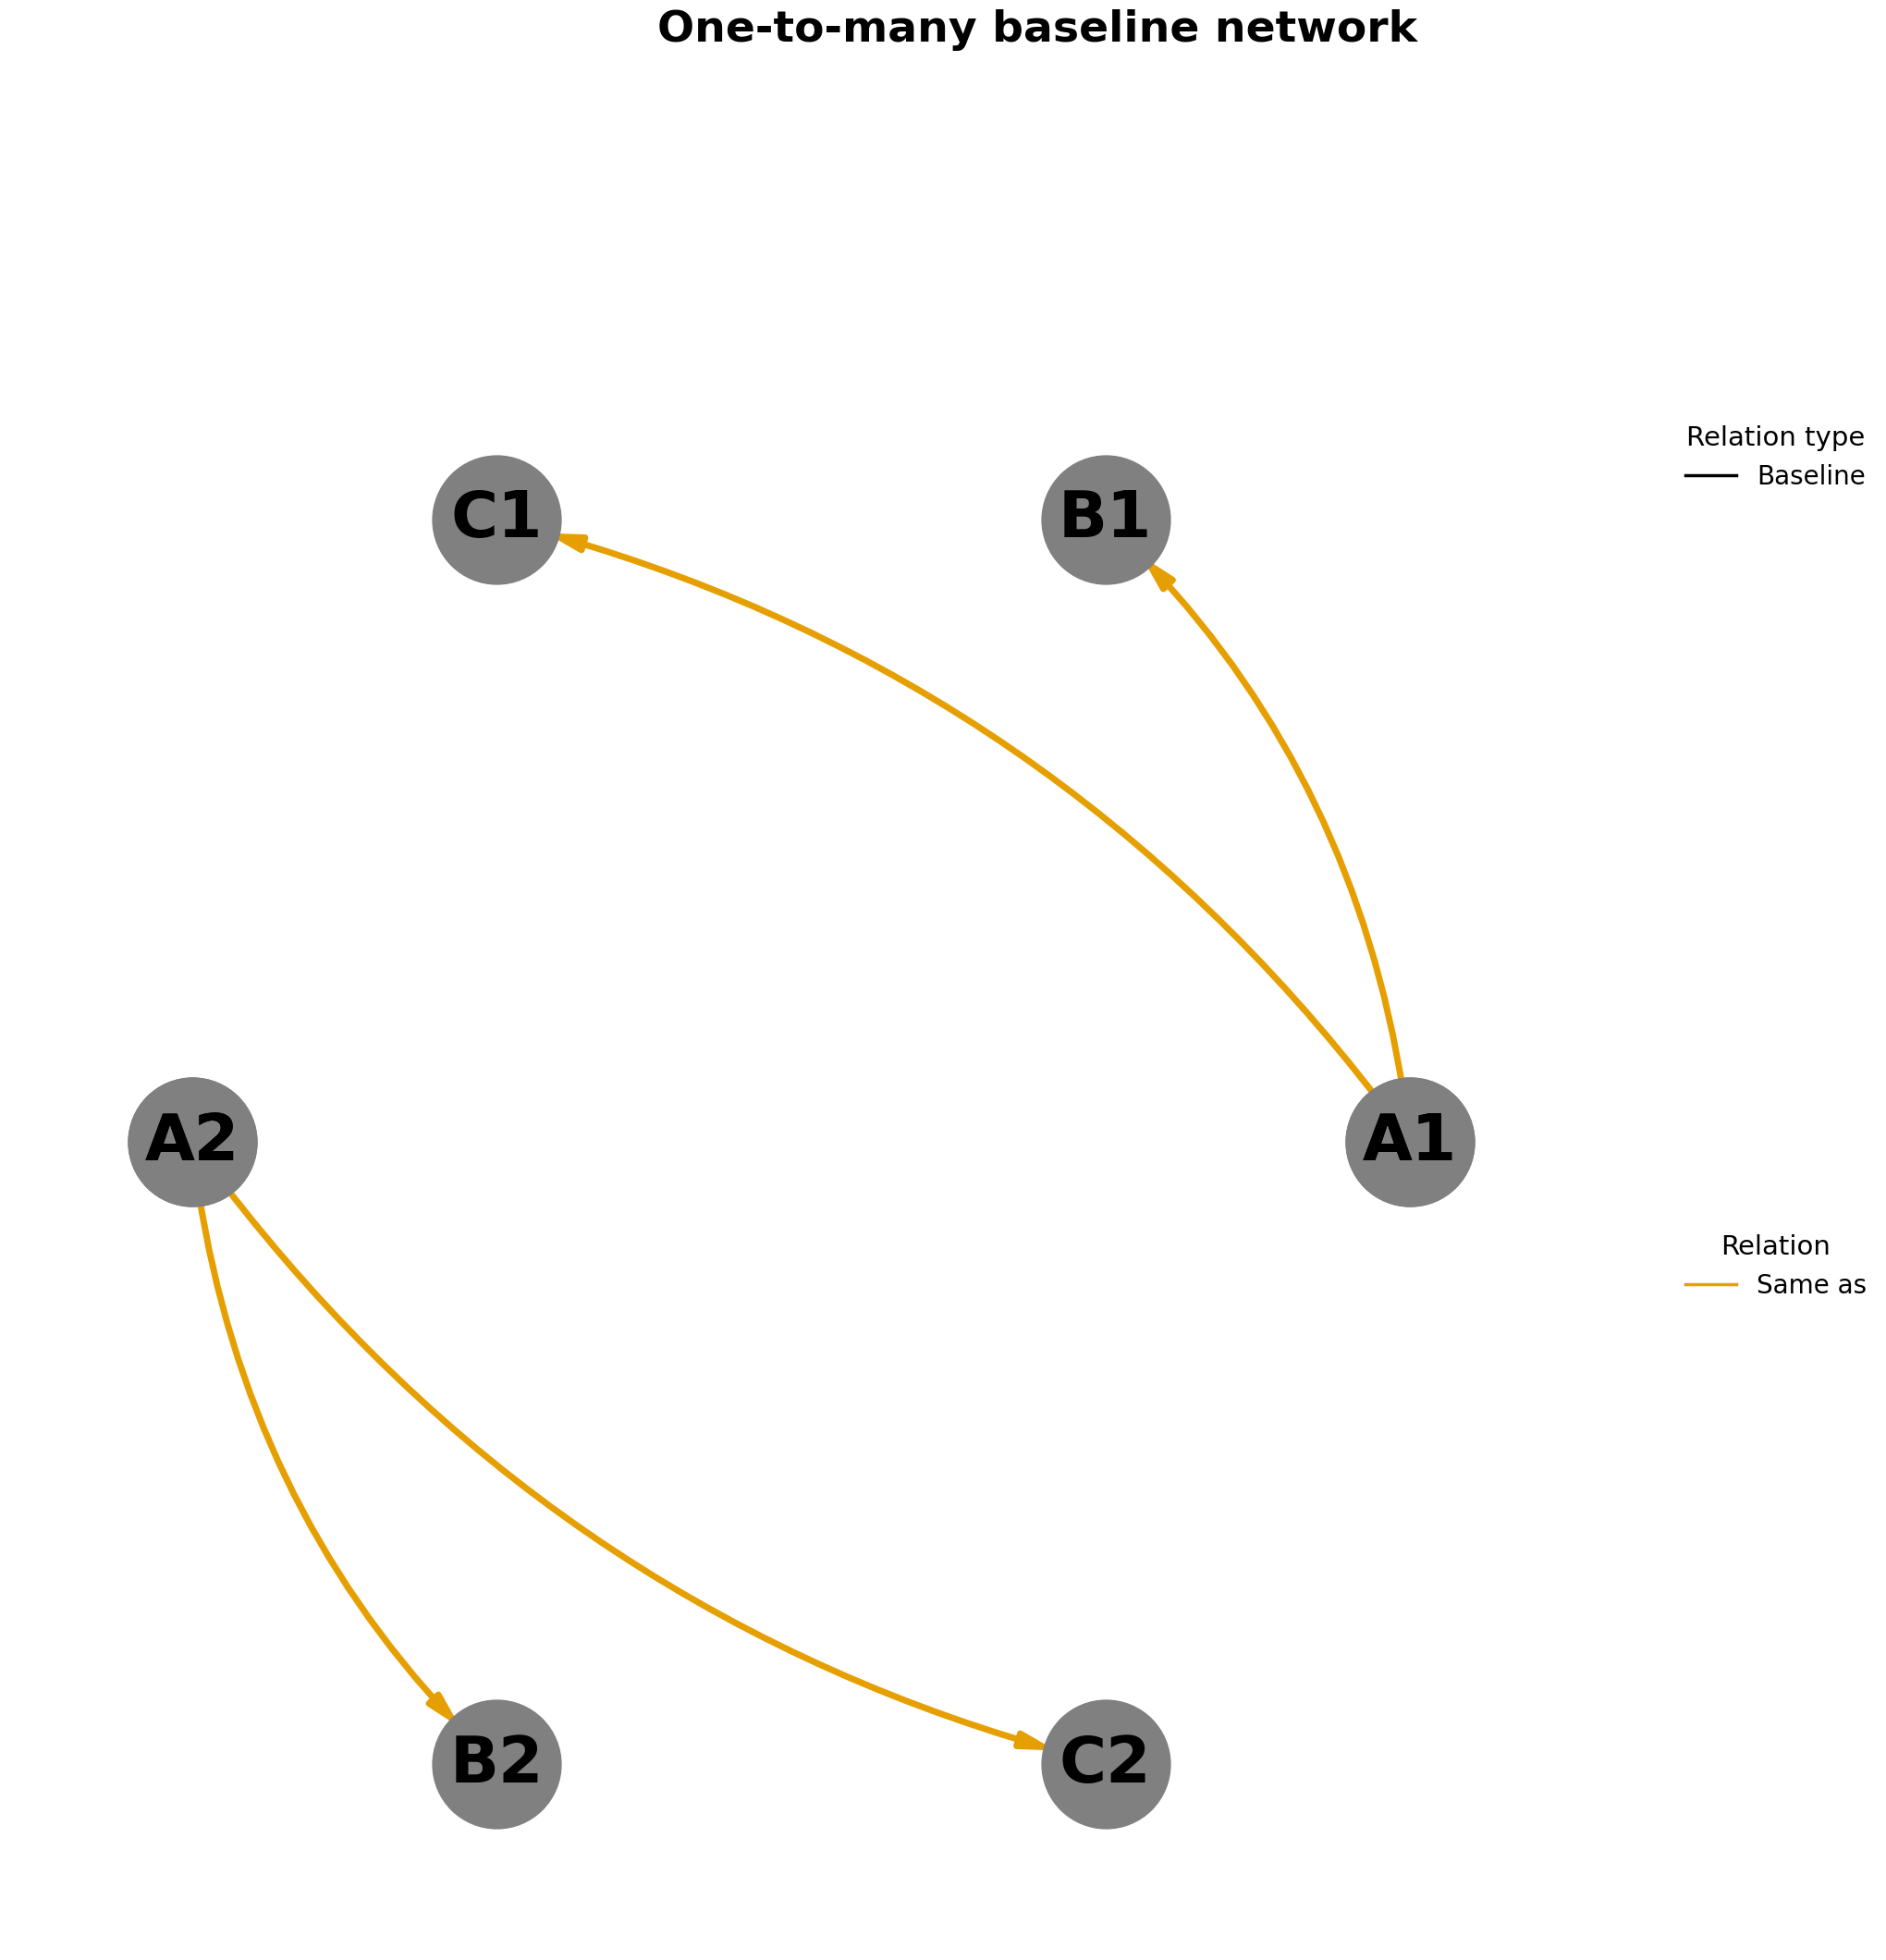

In [83]:
if 'plotRelNetworkGraph' in globals():
    plotRelNetworkGraph(
        structure_baselines['OTM'],
        derived=structure_derivations['OTM']['derived'],
        sLabs=stimuli_classes,
        plotRels=['baseline'],
        plotTitle='One-to-many baseline network',
        layout='circle'
    )

## 3. Generating Matching-to-Sample tasks

`generateTrials()` builds trial-level training and testing schedules from a baseline network. The original notebook uses the **Manual** preset, which lets you define the baseline relation dictionary and stimulus labels directly.

Useful parameters:

| Argument | Purpose | Example |
|---|---|---|
| `baseline` | Trained relations as indexed pairs | `{'Same as': [(0,1), ...]}` |
| `n_baseline` | Repetitions of baseline training relations | `2` or `5` |
| `preset` | Protocol selection; `Manual` uses supplied relations | `'Manual'` |
| `n_test` | Repetitions of derived/test relations | `1` or `3` |
| `n_comp` | Number of presented response alternatives | `3` or `4` |
| `printTrials` | Verbose display of generated trials | `True` / `False` |
| `sLabs` | Display names for stimulus indices | `['A1','B1', ...]` |

**Caution:** `n_comp` includes the correct comparison, so a three-comparison trial has two distractors. Trial counts and labels can vary depending on which derived relations are included by the installed generator.

### 3.1 Small two-class example (three comparison options)

Start with two three-member equivalence classes in a Linear arrangement. Keep verbose printing off and inspect the generated DataFrame directly.

Setting `printTrials=True` prints out the generated MTS trials.

In [84]:
mts_stimuli = ['A1', 'B1', 'C1', 'A2', 'B2', 'C2']
mts_baseline = {
    'Same as': [(0, 1), (1, 2), (3, 4), (4, 5)]
}

np.random.seed(SEED)
mts_small = generateTrials(
    mts_baseline,
    n_baseline=1,
    preset='Manual',
    n_test=1,
    n_comp=3,
    printTrials=True,
    sLabs=mts_stimuli
)



Training Trial 1 (#0, Baseline): Sample stimulus A1 is Same as A2, B1 or C2? 

Correct answer is B1!

Training Trial 2 (#1, Baseline): Sample stimulus B1 is Same as C1, B2 or A2? 

Correct answer is C1!

Training Trial 3 (#2, Baseline): Sample stimulus A2 is Same as A1, C1 or B2? 

Correct answer is B2!

Training Trial 4 (#3, Baseline): Sample stimulus B2 is Same as A1, C1 or C2? 

Correct answer is C2!

Test Trial 1 (#4, Combinatorially entailed): Sample stimulus A1 is Same as C1, B2 or C2? 

Correct answer is C1!

Test Trial 2 (#5, Mutually entailed): Sample stimulus B1 is Same as A1, B2 or A2? 

Correct answer is A1!

Test Trial 3 (#6, Combinatorially entailed): Sample stimulus C1 is Same as B2, A2 or A1? 

Correct answer is A1!

Test Trial 4 (#7, Mutually entailed): Sample stimulus C1 is Same as B1, A2 or B2? 

Correct answer is B1!

Test Trial 5 (#8, Combinatorially entailed): Sample stimulus A2 is Same as A1, B1 or C2? 

Correct answer is C2!

Test Trial 6 (#9, Mutually entailed

### 3.2 More training repetitions and four comparison options

Hold the baseline network constant and increase both the number of baseline repetitions and the number of comparisons. This changes how much training the generator includes and how many response options each trial displays.

In [85]:
np.random.seed(SEED)
mts_four_options = generateTrials(
    mts_baseline,
    n_baseline=5,
    preset='Manual',
    n_test=2,
    n_comp=4,
    printTrials=False,
    sLabs=mts_stimuli
)

print('Number of generated trials with three options:', len(mts_small['tID']), 'total rows')
print('Number of generated trials with four options and more repetitions:', len(mts_four_options['tID']), 'total rows')

Number of generated trials with three options: 12 total rows
Number of generated trials with four options and more repetitions: 36 total rows


### 3.3 Compare training structures with the same trial-generation settings

Let us return to the example of training structures in stimulus equivalence, which provides a helpful use case to produce corresponding MTS tasks for Linear, OTM, and MTO training while leaving `n_baseline`, `n_test`, and `n_comp` fixed. 

In [86]:
mts_by_structure = {}
summary_rows = []
structure_baselines = {
    'Linear': {'Same as': [(0, 1), (1, 2), (3, 4), (4, 5)]},
    'OTM':    {'Same as': [(0, 1), (0, 2), (3, 4), (3, 5)]},
    'MTO':    {'Same as': [(0, 2), (1, 2), (3, 5), (4, 5)]},
}
for name, baseline in structure_baselines.items():
    np.random.seed(SEED)
    print(f'========\nTraining Structure: {name}\n========')
    trials = generateTrials(
        baseline,
        n_baseline=2,
        preset='Manual',
        n_test=1,
        n_comp=3,
        printTrials=True,
        sLabs=stimuli_classes
    )
    mts_by_structure[name] = trials
    row = {'Structure': name, 'Total rows': len(trials)}



Training Structure: Linear

Training Trial 1 (#0, Baseline): Sample stimulus A1 is Same as A2, B1 or C2? 

Correct answer is B1!

Training Trial 2 (#1, Baseline): Sample stimulus B1 is Same as C1, B2 or A2? 

Correct answer is C1!

Training Trial 3 (#2, Baseline): Sample stimulus A2 is Same as A1, C1 or B2? 

Correct answer is B2!

Training Trial 4 (#3, Baseline): Sample stimulus B2 is Same as A1, C1 or C2? 

Correct answer is C2!

Training Trial 5 (#0, Baseline): Sample stimulus A1 is Same as B1, B2 or C2? 

Correct answer is B1!

Training Trial 6 (#1, Baseline): Sample stimulus B1 is Same as C1, B2 or A2? 

Correct answer is C1!

Training Trial 7 (#2, Baseline): Sample stimulus A2 is Same as B1, A1 or B2? 

Correct answer is B2!

Training Trial 8 (#3, Baseline): Sample stimulus B2 is Same as C2, A1 or B1? 

Correct answer is C2!

Test Trial 1 (#4, Combinatorially entailed): Sample stimulus A1 is Same as A2, B2 or C1? 

Correct answer is C1!

Test Trial 2 (#5, Mutually entailed): Samp

### 3.4 Generating the Steele and Hayes (1991) MTS Procedure



In [87]:
baseline = dict({'Same as': [(0,1), (0,4)],
                'Different from': [(0, 2), (0,5)],
                'Opposite to': [(0, 3), (0,6)]})
sLabs = ['A', 'B1', 'B2', 'B3', 'C1', 'C2', 'C3', 'N1', 'N2']

trial_data = generateTrials(
    baseline=baseline,
    n_baseline = 1,
    preset = 'Manual',
    n_test = 1,
    n_comp =3,
    # derived=derived,
    printTrials = True,
    sLabs=sLabs
)


Training Trial 1 (#0, Baseline): Sample stimulus A is Same as B1, B2 or N1? 

Correct answer is B1!

Training Trial 2 (#1, Baseline): Sample stimulus A is Same as N2, C1 or B3? 

Correct answer is C1!

Training Trial 3 (#2, Baseline): Sample stimulus A is Different from B2, C1 or B1? 

Correct answer is B2!

Training Trial 4 (#3, Baseline): Sample stimulus A is Different from B1, C2 or N2? 

Correct answer is C2!

Training Trial 5 (#4, Baseline): Sample stimulus A is Opposite to N2, B3 or C1? 

Correct answer is B3!

Training Trial 6 (#5, Baseline): Sample stimulus A is Opposite to C3, C1 or N2? 

Correct answer is C3!

Test Trial 1 (#6, Mutually entailed): Sample stimulus B1 is Same as B2, A or B3? 

Correct answer is A!

Test Trial 2 (#7, Combinatorially entailed): Sample stimulus B1 is Same as C3, N2 or C1? 

Correct answer is C1!

Test Trial 3 (#8, Combinatorially entailed): Sample stimulus B3 is Same as N2, C3 or N1? 

Correct answer is C3!

Test Trial 4 (#9, Mutually entailed): 

### 3.5 A larger OTM network 

This revisits the original notebook's four-member class example. To keep the output readable, verbose printing is enabled with only one repetition of each training/test relation. The stimulus list can include additional labels that are not connected by the trained baseline; those labels should not be confused with explicitly trained class members.

In [88]:
mts_large_labels = [
    'A1', 'A2', 'A3', 'A4',
    'B1', 'B2', 'B3', 'B4',
    'C1', 'C2', 'C3', 'C4',
    'D1', 'D2', 'D3', 'D4'
]
mts_large_baseline = {
    'Same as': [(0, 1), (0, 2), (0, 3),
                (4, 5), (4, 6), (4, 7)]
}

np.random.seed(SEED)
mts_large = generateTrials(
    mts_large_baseline,
    n_baseline=1,
    preset='Manual',
    n_test=1,
    n_comp=4,
    printTrials=True,
    sLabs=mts_large_labels
)
print('Generated rows:', len(mts_large))


Training Trial 1 (#0, Baseline): Sample stimulus A1 is Same as B1, A2, B4 or B2? 

Correct answer is A2!

Training Trial 2 (#1, Baseline): Sample stimulus A1 is Same as C1, A3, D3 or B2? 

Correct answer is A3!

Training Trial 3 (#2, Baseline): Sample stimulus A1 is Same as C4, A4, B4 or D3? 

Correct answer is A4!

Training Trial 4 (#3, Baseline): Sample stimulus B1 is Same as B2, A1, C3 or C1? 

Correct answer is B2!

Training Trial 5 (#4, Baseline): Sample stimulus B1 is Same as C2, C1, A1 or B3? 

Correct answer is B3!

Training Trial 6 (#5, Baseline): Sample stimulus B1 is Same as D1, A2, B4 or D4? 

Correct answer is B4!

Test Trial 1 (#6, Mutually entailed): Sample stimulus A2 is Same as D4, A1, B1 or C4? 

Correct answer is A1!

Test Trial 2 (#7, Combinatorially entailed): Sample stimulus A2 is Same as C1, D2, B3 or A3? 

Correct answer is A3!

Test Trial 3 (#8, Combinatorially entailed): Sample stimulus A2 is Same as C4, D2, C3 or A4? 

Correct answer is A4!

Test Trial 4 (#9

### 3.6 Save a generated trial schedule

Exporting as CSV is convenient for inspection or subsequent task programming. For columns containing Python lists (e.g., multiple comparison labels), CSV preserves a textual representation; **pickle or Parquet may better retain Python object types** if you need to load the schedule back without parsing.

In [ ]:
# Uncomment the next two lines to save an example in your working directory.
# output_path = Path('mts_example_schedule.csv')
# mts_small.to_csv(output_path, index=False)

print('Example columns available for export:', list(mts_small.columns))

## 4. Generating relational syllogisms

`generateSyllogism()` constructs reasoning problems from relational premises. Unlike an MTS trial, a syllogism presents **multiple premises** and asks the participant to evaluate possible conclusions or statements.

The original notebook demonstrates a typical n-term reasoning task using comparative dimensions (faster/slower and stronger/weaker), named relata, and both incorrect and mutually entailed conclusions.

Key options include:

- `relations`: relational vocabulary used in the problems;
- `premises_types`: problem types selected for different numbers of premises;
- `n_rep`: repetition count;
- `relata`: content used for stimulus names (the supplied example uses `'names'`);
- `protocol`: structure used to generate the premises;
- `n_opt`: number of response options;
- `printTrials`: print examples while generating.

The specific keys accepted by `premises_types` and additional `protocol` values are defined by your installed package. The examples below use combinations already present in the original notebook.

### 4.1 Four relational terms, two to four premises

This is the original example, now with a short inspection of the returned trials.

In [94]:

# typical syllogistic n-term reasoning task relations x names
syllogism_relations = ['faster', 'slower', 'stronger', 'weaker']
# include 'incorrect' conclusions and reversal of transitive derived relations
premises_types = {'2': ['Incorrect', 'MutualCE'],
                  '3': ['Incorrect', 'MutualCE'],
                  '4': ['Incorrect', 'MutualCE']
                  }

syllogisms_full = generateSyllogism(relations = relations, 
                               premises_types = premises_types, 
                               n_rep = 4, 
                               relata = 'names',
                               protocol = 'Linear',
                               n_opt = 3,
                               printTrials = False)
print('Generated trials:', len(syllogisms_full))
display(syllogisms_full.head(5))

Generated trials: 12


,id,Premises,Relations,Prompt,Correct,printCorrect,n_p,Derivation,Type
0,2,"[Bart is the same as John., John is the same a...","[Same as, Same as]",Bart is the same as John. John is the same as ...,"[0, 1, 0]","[no select, select, no select]",2,Combinatorial,Regular
1,4,"[Mark is the same as Jane., Jane is the same a...","[Same as, Same as]",Mark is the same as Jane. Jane is the same as ...,"[1, 0, 0]","[select, no select, no select]",2,Combinatorial,Regular
2,6,"[Jake is the same as Lisa., Lisa is the same a...","[Same as, Same as]",Jake is the same as Lisa. Lisa is the same as ...,"[0, 0, 1]","[no select, no select, select]",2,Combinatorial,Regular
3,8,"[Sam is the same as Chris., Chris is the same ...","[Same as, Same as]",Sam is the same as Chris. Chris is the same as...,"[1, 0, 0]","[select, no select, no select]",2,Combinatorial,Regular
4,10,"[Bart is the same as John., John is the same a...","[Same as, Same as, Same as]",Bart is the same as John. John is the same as ...,"[0, 0, 1]","[no select, no select, select]",3,Combinatorial,Regular


### 4.2 Shorter problems with fewer response options

To create a briefer teaching or pilot task, restrict the problem specification to two premises, use fewer repetitions, and reduce the number of answer options. Before running a real experiment, inspect the correct-answer field and whether multiple responses can be valid.

In [95]:
np.random.seed(SEED)
syllogisms_short = generateSyllogism(
    relations=syllogism_relations,
    premises_types={'2': ['Incorrect', 'MutualCE']},
    n_rep=1,
    relata='names',
    protocol='Linear',
    n_opt=2,
    printTrials=False
)
print('Brief task rows:', len(syllogisms_short))
display(syllogisms_short.head(3))

Brief task rows: 6


,id,Premises,Relations,Prompt,Correct,printCorrect,n_p,Derivation,Type
0,2,"[Bart is faster than John., John is faster tha...","[Faster than, Faster than]",Bart is faster than John. John is faster than ...,"[0, 1]","[no select, select]",2,Combinatorial,Regular
1,6,"[Jake is slower than Lisa., Lisa is slower tha...","[Slower than, Slower than]",Jake is slower than Lisa. Lisa is slower than ...,"[1, 0]","[select, no select]",2,Combinatorial,Regular
2,8,"[Megan is lower than Archie., Archie is lower ...","[Lower than, Lower than]",Megan is lower than Archie. Archie is lower th...,"[0, 1]","[no select, select]",2,Combinatorial,Regular


### 4.3 Preview three randomly selected syllogisms

The preview displays available output fields without assuming the exact schema of every version of the generator. The same utility can be used to check task content before exporting trials to an experimental platform.

In [96]:
def preview_syllogisms(df, n=3, seed=SEED):
    if df.empty:
        print('No trials were generated.')
        return
    sample = df.sample(n=min(n, len(df)), random_state=seed)
    for j, (_, trial) in enumerate(sample.iterrows(), start=1):
        print(f'\n--- Syllogism {j} ---')
        for name in ('Type', 'Premises', 'Prompt', 'printCorrect'):
            if name in trial.index:
                value = trial[name]
                if isinstance(value, (list, tuple)):
                    value = ' '.join(map(str, value))
                print(f'{name}: {value}')
        remaining = [name for name in ('Correct', 'Options', 'Responses') if name in trial.index]
        for name in remaining:
            print(f'{name}: {trial[name]}')

preview_syllogisms(syllogisms_full)


--- Syllogism 1 ---
Type: Regular
Premises: Macie is the same as Grace. Grace is the same as Jack. Jack is the same as Mike. Mike is the same as Fiona.
Prompt: Macie is the same as Grace. Grace is the same as Jack. Jack is the same as Mike. Mike is the same as Fiona. Select the TRUE statement from the options below. 
1. Macie is less than Fiona. 
2. Fiona is the same as Macie. 
3. Fiona is opposite to Macie.
printCorrect: no select select no select
Correct: [0, 1, 0]

--- Syllogism 2 ---
Type: Regular
Premises: Chris is the same as Joe. Joe is the same as Megan. Megan is the same as Archie. Archie is the same as Charlie.
Prompt: Chris is the same as Joe. Joe is the same as Megan. Megan is the same as Archie. Archie is the same as Charlie. Select the TRUE statement from the options below. 
1. Chris is more than Charlie. 
2. Chris is the same as Charlie. 
3. I need more information to derive the relation between Charlie and Chris.
printCorrect: no select select no select
Correct: [0, 1,

### 4.4 Compare complexity settings

For a transparent parameter check, this final syllogism example prints the number of generated rows and any available type counts for the shorter and fuller task variants. More rows do not by themselves establish higher psychological difficulty; difficulty also depends on the relational rules and how many relational compositions the task requires.

In [97]:
for label, trials in [('Brief (2 premises)', syllogisms_short),
                      ('Full (2–4 premises)', syllogisms_full)]:
    print(f'\n{label}: {len(trials)} rows')
    if 'Type' in trials.columns:
        print(trials['Type'].value_counts().to_string())

# Optional export:
# syllogisms_full.to_csv('relational_syllogisms.csv', index=False)


Brief (2 premises): 6 rows
Type
Regular    6

Full (2–4 premises): 12 rows
Type
Regular    12


### 4.5 Generate your own syllogisms

In the cell below, you can specify the relations and task settings for which to generate syllogistic problems. Set relations,  

In [98]:
syllogism_relations = [] # <-- Add relations here!
syllogism_types = {
    '2': ['Incorrect', 'MutualCE'], # remove or add 'Analogy', 'ToF', 'Irrelevant'
    '3': ['Incorrect', 'MutualCE'], # remove or add 'Analogy', 'ToF', 'Irrelevant'
    '4': ['Incorrect', 'MutualCE'], # remove or add 'Analogy', 'ToF', 'Irrelevant'
}

n_rep = 1 # <-- set how many repetitions of each problem to generate
n_opt = 3 # <-- you can change the number of response options
relata = 'names' # <-- choose from 'names' / 'nonwords' / 'alphanumerics'
np.random.seed(SEED)
syllogisms_full = generateSyllogism(
    relations=syllogism_relations,
    premises_types=syllogism_types,
    n_rep=n_rep,
    relata=relata,
    protocol='Linear',
    n_opt=n_opt,
    printTrials=False
)
print('Generated trials:', len(syllogisms_full))
display(syllogisms_full.head(5))

Generated trials: 0


""


## 5. Choosing an appropriate workflow

| Research or development goal | Recommended tool | Useful parameter changes |
|---|---|---|
| Define which relational transformations are permitted | `createDerivationTables` | Relation vocabulary; `plotTables` |
| Inspect a symbolic network's implied relations | `deriveRelationsFromBaseline` | Baseline pairs; `illustrate`; `max_depth` |
| Present a relational network visually | `plotRelNetworkGraph` or `illustrate='graph'` | Layout; displayed relation categories; labels |
| Generate a basic equivalence-class MTS task | `generateTrials` | Training structure; `n_baseline`; `n_test`; `n_comp` |
| Construct longer chains for transitive inference | `deriveRelationsFromBaseline` | Comparison network; chain length; depth |
| Generate multi-premise verbal reasoning problems | `generateSyllogism` | Relation terms; premise types; repetitions; response options |

### Practical checks before using generated material in a study

1. **Check relation indices:** all baseline pairs should refer to valid entries in the supplied stimulus list.
2. **Check trial types and keys:** inspect the returned DataFrame rather than assuming the same column names across software versions.
3. **Check comparison lists:** make sure each trial contains the intended number of response options and one appropriate keyed response.
4. **Check derived outcomes:** review a small network manually, especially when using newly added relational vocabularies.
5. **Check reproducibility:** save random seeds, package versions, training definitions, and exported trial files.
6. **Distinguish symbolic derivation from learning:** symbolic closure computes consequences from specified relations; reinforcement-learning simulations additionally model acquisition, response values, and stochastic selection.

### Possible extensions

Further examples could include contextual control with conditional discriminations, network layouts with user-defined node positions, deictic-relational syllogisms, or direct comparisons with the goal-directed Q-value derivation engine. Such demonstrations require checking the relevant function interfaces and, for reinforcement learning, the corresponding model implementation.

## 6. Environment and reproducibility record

Run this cell when sharing a notebook or reporting an experiment. It records the Python/library versions and working directory without modifying generated stimuli or trials.

In [99]:
import sys
from importlib import metadata

print('Python:', sys.version.split()[0])
print('Working directory:', Path.cwd())
for pkg in ('numpy', 'pandas', 'matplotlib', 'seaborn', 'derTables'):
    try:
        print(f'{pkg}: {metadata.version(pkg)}')
    except metadata.PackageNotFoundError:
        print(f'{pkg}: package version not available via metadata')

print('Random seed used in examples:', SEED)

Python: 3.11.14
Working directory: C:\Users\mraemaek\OneDrive\Documenten\UGent stuff\Ghent_PhD\Projects\Modelling\DerivationTableApplications\Scripts
numpy: 2.4.2
pandas: 3.0.1
matplotlib: 3.10.8
seaborn: 0.13.2
derTables: package version not available via metadata
Random seed used in examples: 2026
